Initial class distribution:
belly_pain: 16 samples
burping: 8 samples
discomfort: 27 samples
hungry: 382 samples
tired: 24 samples
belly_pain data is loading...
belly_pain data loaded with augmentation...
burping data is loading...
burping data loaded with augmentation...
discomfort data is loading...
discomfort data loaded with augmentation...
hungry data is loading...
hungry data loaded with augmentation...
tired data is loading...
tired data loaded with augmentation...

Class distribution after augmentation:
belly_pain: 176 samples
burping: 88 samples
discomfort: 297 samples
hungry: 382 samples
tired: 264 samples
Train-Test Split Seed: 3225806193
Random Forest Seed: 3613533475
Training data shape after SMOTE: (1525, 1229)
Number of features: 1229


c:\Users\visha\OneDrive\Desktop\data\myenv\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


Accuracy: 0.9793, F1 Score: 0.9793, Recall: 0.9793, Runtime: 1.53 sec


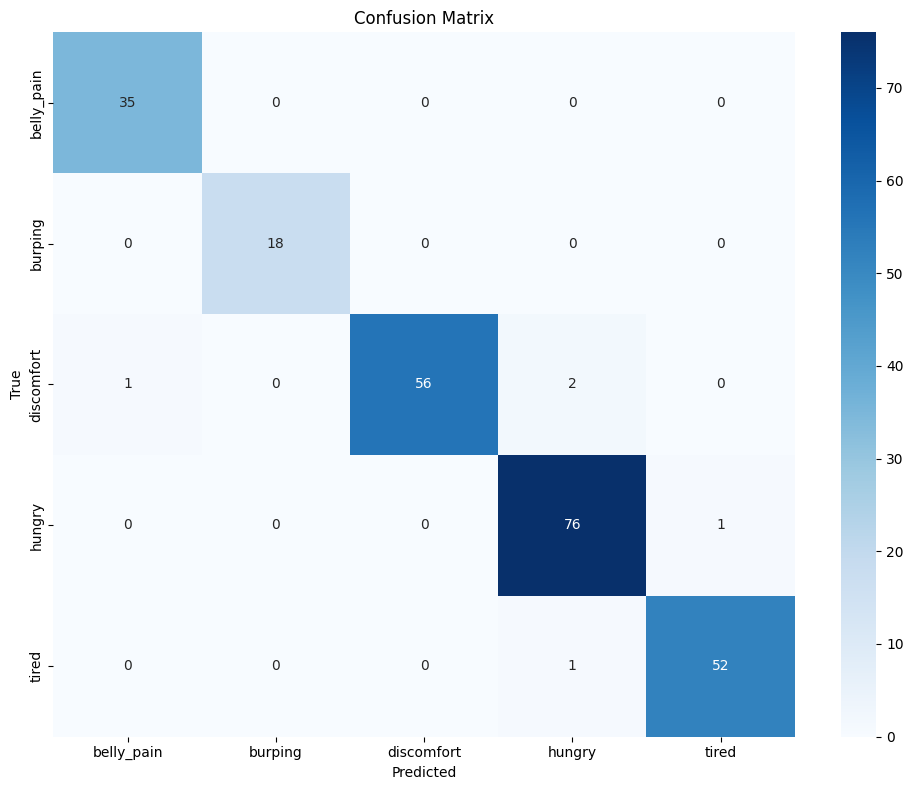

C:\Users\visha\AppData\Local\Temp\ipykernel_8936\3205028650.py:309: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(top_importance), y=list(top_features), palette="viridis")


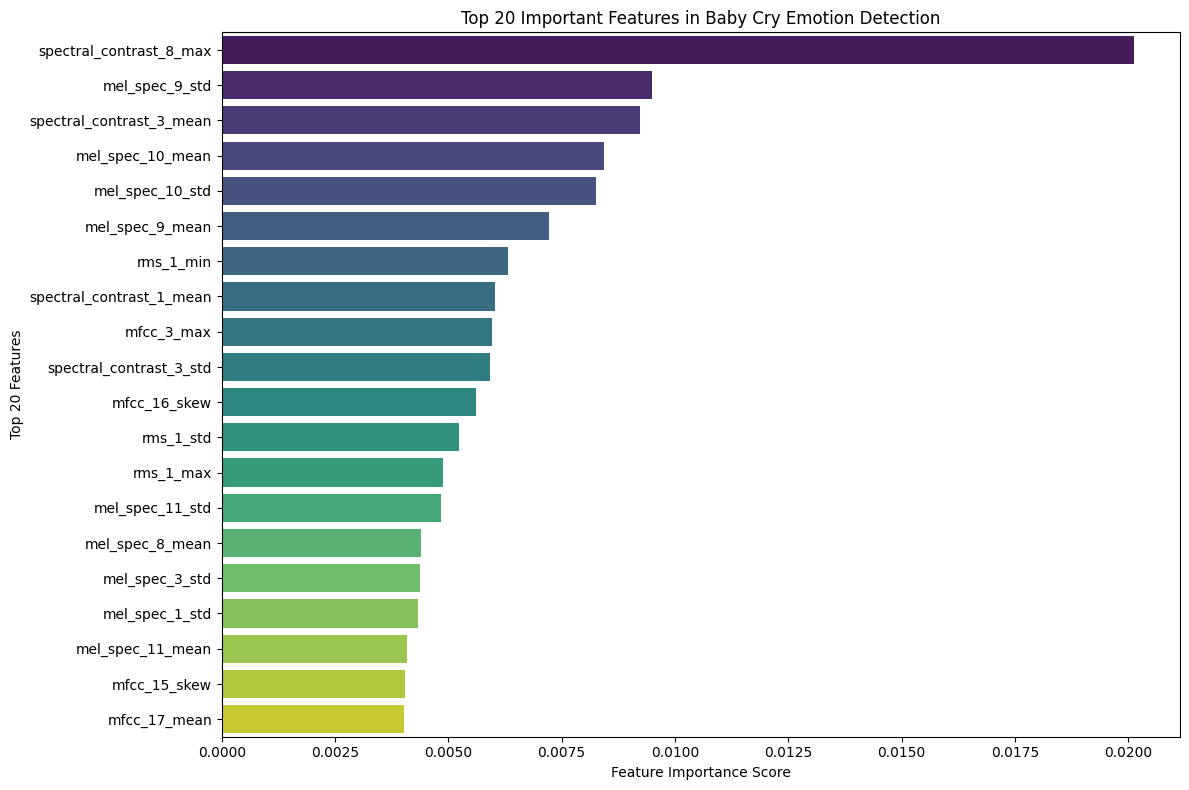


Top 20 Important Features:
spectral_contrast_8_max: 0.0201
mel_spec_9_std: 0.0095
spectral_contrast_3_mean: 0.0092
mel_spec_10_mean: 0.0084
mel_spec_10_std: 0.0083
mel_spec_9_mean: 0.0072
rms_1_min: 0.0063
spectral_contrast_1_mean: 0.0060
mfcc_3_max: 0.0060
spectral_contrast_3_std: 0.0059
mfcc_16_skew: 0.0056
rms_1_std: 0.0052
rms_1_max: 0.0049
mel_spec_11_std: 0.0048
mel_spec_8_mean: 0.0044
mel_spec_3_std: 0.0044
mel_spec_1_std: 0.0043
mel_spec_11_mean: 0.0041
mfcc_15_skew: 0.0040
mfcc_17_mean: 0.0040
Model saved as 'baby_cry_model.pkl'


In [ ]:
import os
import numpy as np
import librosa
import scipy.signal as signal
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix
import time
import random
from imblearn.over_sampling import SMOTE
from collections import Counter
from scipy.stats import skew, kurtosis

SEED = 12345  # You can change this to any integer you want
np.random.seed(SEED)
random.seed(SEED)

# **Pre-emphasis Function**
def pre_emphasis(signal, alpha=0.97):
    return np.append(signal[0], signal[1:] - alpha * signal[:-1])

# **Bandpass Filter Function (142.91 Hz - 6620.12 Hz)**
def bandpass_filter(y, sr=16000, lowcut=142.91, highcut=6620.12, order=5):
    nyquist = 0.5 * sr
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = signal.butter(order, [low, high], btype='band')
    return signal.filtfilt(b, a, y)


def extract_features(audio_data, sr=16000, n_mfcc=40, n_fft=1024, hop_length=160, win_length=400, window='hann',
                     n_chroma=12, n_mels=13, n_bands=7, fmin=100, bins_per_octave=12, tempogram_win=384, spectral_roll_percent=0.95):
    try:
        # Apply Pre-emphasis
        y = pre_emphasis(audio_data, alpha=0.97)

        # Apply Bandpass Filter
        y = bandpass_filter(y, sr=sr)

        # Zero Crossing Rate & RMS
        zcr = librosa.feature.zero_crossing_rate(y, frame_length=win_length, hop_length=hop_length)
        rms = librosa.feature.rms(y=y, frame_length=win_length, hop_length=hop_length)

        # STFT and Spectral Features
        stft = np.abs(librosa.stft(y, n_fft=n_fft, hop_length=hop_length, win_length=win_length))
        S, phase = librosa.magphase(stft)

        # MFCC and Deltas
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc, n_fft=n_fft, hop_length=hop_length,
                                   win_length=win_length, window=window)
        mfcc_delta = librosa.feature.delta(mfcc)
        mfcc_delta2 = librosa.feature.delta(mfcc, order=2)

        # Advanced Spectral Features
        spectral_centroid = librosa.feature.spectral_centroid(S=S, sr=sr)
        spectral_bandwidth = librosa.feature.spectral_bandwidth(S=S, sr=sr)
        spectral_rolloff = librosa.feature.spectral_rolloff(S=S, sr=sr, roll_percent=spectral_roll_percent)
        spectral_contrast = librosa.feature.spectral_contrast(S=S, sr=sr, n_bands=n_bands, fmin=fmin)
        chroma = librosa.feature.chroma_stft(S=S, sr=sr, n_chroma=n_chroma)
        mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length,
                                                 win_length=win_length, n_mels=n_mels)
        tonnetz = librosa.feature.tonnetz(y=y, sr=sr)

        # Temporal Features

        # Feature aggregation with statistics
        feature_functions = [
            (mfcc, 'mfcc', ['mean', 'std', 'skew', 'max', 'min']),
            (mfcc_delta, 'mfcc_delta', ['mean', 'std']),
            (mfcc_delta2, 'mfcc_delta2', ['mean', 'std']),
            (zcr, 'zcr', ['mean', 'std', 'max']),
            (rms, 'rms', ['mean', 'std', 'max', 'min']),
            (spectral_centroid, 'spectral_centroid', ['mean', 'std', 'max']),
            (spectral_bandwidth, 'spectral_bandwidth', ['mean', 'std', 'max']),
            (spectral_rolloff, 'spectral_rolloff', ['mean', 'std']),
            (spectral_contrast, 'spectral_contrast', ['mean', 'std', 'max']),
            (chroma, 'chroma', ['mean', 'std']),
            (mel_spec, 'mel_spec', ['mean', 'std']),
            (tonnetz, 'tonnetz', ['mean', 'std']),
        ]

        features = []
        feature_names = []

        for feat, feat_name, stats in feature_functions:
            for i in range(feat.shape[0]):
                if 'mean' in stats: 
                    features.append(np.mean(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_mean")
                if 'std' in stats: 
                    features.append(np.std(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_std")
                if 'skew' in stats: 
                    features.append(skew(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_skew")
                if 'kurt' in stats: 
                    features.append(kurtosis(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_kurt")
                if 'max' in stats: 
                    features.append(np.max(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_max")
                if 'min' in stats: 
                    features.append(np.min(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_min")

        # Return both features and their names
        return np.array(features), feature_names
    except Exception as e:
        print(f"Error processing audio data: {e}")
        return None, None


# **Data Augmentation Functions**
def time_stretching(y, rate):
    """Time stretching without changing pitch"""
    return librosa.effects.time_stretch(y, rate=rate)

def pitch_shifting(y, sr, n_steps):
    """Pitch shifting without changing tempo"""
    return librosa.effects.pitch_shift(y, sr=sr, n_steps=n_steps)

def add_noise(y, noise_factor=0.005):
    """Add random noise to the audio"""
    noise = np.random.randn(len(y))
    return y + noise_factor * noise

def random_gain(y, min_factor=0.7, max_factor=1.3):
    """Apply random gain to the audio"""
    gain_factor = np.random.uniform(min_factor, max_factor)
    return y * gain_factor

def time_shifting(y, shift_factor=0.2):
    """Shift audio in time (circular shift)"""
    shift_amount = int(len(y) * shift_factor)
    return np.roll(y, shift_amount)

def augment_audio(y, sr):
    """Apply random augmentation technique to audio"""
    augmentation_techniques = [
        lambda: time_stretching(y, rate=np.random.uniform(0.85, 1.15)),
        lambda: pitch_shifting(y, sr, n_steps=np.random.uniform(-2, 2)),
        lambda: add_noise(y, noise_factor=np.random.uniform(0.001, 0.01)),
        lambda: random_gain(y),
        lambda: time_shifting(y, shift_factor=np.random.uniform(0.1, 0.3))
    ]
    
    # Randomly select two augmentation techniques
    chosen_techniques = np.random.choice(len(augmentation_techniques), size=2, replace=False)
    
    augmented_y = y.copy()
    for idx in chosen_techniques:
        augmented_y = augmentation_techniques[idx]()
    
    return augmented_y

# Global variable to store feature names
all_feature_names = []

# **Load Dataset with Augmentation**
path = r"C:\Users\visha\OneDrive\Desktop\SEM6\Speech Processing\datasets\donateacry_corpus"
features = []
labels = []

# Get initial class counts to determine augmentation needed
initial_counts = {}
for label in os.listdir(path):
    file_count = len(os.listdir(os.path.join(path, label)))
    initial_counts[label] = file_count
    
print("Initial class distribution:")
for label, count in initial_counts.items():
    print(f"{label}: {count} samples")

# Find majority class
majority_class_count = max(initial_counts.values())

# **Extract Features with Augmentation**
for label in os.listdir(path):
    print(f"{label} data is loading...")
    label_files = os.listdir(os.path.join(path, label))
    augmentation_factor = int(np.ceil(majority_class_count / len(label_files))) - 1
    
    # Process original files
    for file_name in label_files:
        file_path = os.path.join(path, label, file_name)
        
        # Load audio file
        y, sr = librosa.load(file_path, sr=16000)
        
        # Extract features from original audio
        feature, feature_names = extract_features(y, sr=sr)
        if feature is not None:
            features.append(feature)
            labels.append(label)
            
            # Store feature names only once
            if not all_feature_names and feature_names is not None:
                all_feature_names = feature_names
        
        # Apply augmentation if needed (for minority classes)
        if augmentation_factor > 0:
            for _ in range(min(augmentation_factor, 10)):  # Cap at 10 augmentations per file
                augmented_y = augment_audio(y, sr)
                augmented_feature, _ = extract_features(augmented_y, sr=sr)
                if augmented_feature is not None:
                    features.append(augmented_feature)
                    labels.append(label)
    
    print(f"{label} data loaded with augmentation...")

# Check if feature dimensions are consistent
feature_lengths = [len(f) for f in features]
if len(set(feature_lengths)) > 1:
    print(f"Warning: Inconsistent feature lengths detected: {set(feature_lengths)}")
    # Find the most common length
    from collections import Counter
    most_common_length = Counter(feature_lengths).most_common(1)[0][0]
    
    # Filter to keep only features with the most common length
    valid_indices = [i for i, length in enumerate(feature_lengths) if length == most_common_length]
    features = [features[i] for i in valid_indices]
    labels = [labels[i] for i in valid_indices]
    print(f"Filtered to {len(features)} samples with consistent feature length of {most_common_length}")

# **Convert to NumPy Arrays**
features = np.array(features)
labels = np.array(labels)

# Show class distribution after augmentation
print("\nClass distribution after augmentation:")
for label, count in Counter(labels).items():
    print(f"{label}: {count} samples")

# **Encode Labels**
le = LabelEncoder()
labels = le.fit_transform(labels)

# **Generate Random Seeds**
split_seed = 3225806193
model_seed = 3613533475

# **Print the Seeds Used**
print(f"Train-Test Split Seed: {split_seed}")
print(f"Random Forest Seed: {model_seed}")

# **Split Data**
X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.20, random_state=split_seed, stratify=labels)

# Apply SMOTE for balancing the training data
smote = SMOTE(random_state=model_seed)
X_train, y_train = smote.fit_resample(X_train, y_train)

print(f"Training data shape after SMOTE: {X_train.shape}")
print(f"Number of features: {X_train.shape[1]}")

# **Train Weighted Random Forest Classifier**
start_time = time.time()
rf = RandomForestClassifier(
    n_estimators=500, 
    max_depth=20, 
    class_weight="balanced", 
    random_state=model_seed,
    n_jobs=-1  # Use all available cores
)
rf.fit(X_train, y_train)
runtime = time.time() - start_time

# **Predict**
y_pred = rf.predict(X_test)

# **Evaluate Performance**
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")

# **Print Results**
print(f"Accuracy: {accuracy:.4f}, F1 Score: {f1:.4f}, Recall: {recall:.4f}, Runtime: {runtime:.2f} sec")

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)
class_names = le.classes_

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.savefig('confusion_matrix.png')
plt.show()

# Get feature importances
if len(all_feature_names) == X_train.shape[1]:
    feature_importances = rf.feature_importances_
    feature_importance_dict = dict(zip(all_feature_names, feature_importances))
    
    # **Sort and Get Top 20 Features**
    sorted_features = sorted(feature_importance_dict.items(), key=lambda x: x[1], reverse=True)[:20]
    top_features, top_importance = zip(*sorted_features)
    
    # Print top 20 features with importance sco
    
    # **Plot Feature Importance**
    plt.figure(figsize=(12, 8))
    sns.barplot(x=list(top_importance), y=list(top_features), palette="viridis")
    plt.xlabel("Feature Importance Score")
    plt.ylabel("Top 20 Features")
    plt.title("Top 20 Important Features in Baby Cry Emotion Detection")
    plt.tight_layout()
    plt.savefig('feature_importance.png')
    plt.show()
    
    # Print top 20 features with importance scores
    print("\nTop 20 Important Features:")
    for feature, importance in sorted_features:
        print(f"{feature}: {importance:.4f}")
else:
    print(f"Error: Feature names count ({len(all_feature_names)}) doesn't match feature count ({X_train.shape[1]})")
    # Use generic feature names as fallback
    generic_feature_names = [f"feature_{i}" for i in range(X_train.shape[1])]
    feature_importances = rf.feature_importances_
    feature_importance_dict = dict(zip(generic_feature_names, feature_importances))
    
    # Sort and get top 20
    sorted_features = sorted(feature_importance_dict.items(), key=lambda x: x[1], reverse=True)[:20]
    top_features, top_importance = zip(*sorted_features)
    
    plt.figure(figsize=(12, 8))
    sns.barplot(x=list(top_importance), y=list(top_features), palette="viridis")
    plt.xlabel("Feature Importance Score")
    plt.ylabel("Top 20 Features")
    plt.title("Top 20 Important Features in Baby Cry Emotion Detection")
    plt.tight_layout()
    plt.savefig('feature_importance.png')
    plt.show()

# Save the model and feature names for future use
import pickle
model_info = {
    'model': rf,
    'feature_names': all_feature_names,
    'class_names': class_names,
    'performance': {
        'accuracy': accuracy,
        'f1': f1,
        'recall': recall
    }
}

with open('baby_cry_model.pkl', 'wb') as f:
    pickle.dump(model_info, f)

print("Model saved as 'baby_cry_model.pkl'")

Initial class distribution:
belly_pain: 16 samples
burping: 8 samples
discomfort: 27 samples
hungry: 382 samples
tired: 24 samples
belly_pain data is loading...
belly_pain data loaded with augmentation...
burping data is loading...
burping data loaded with augmentation...
discomfort data is loading...
discomfort data loaded with augmentation...
hungry data is loading...
hungry data loaded with augmentation...
tired data is loading...
tired data loaded with augmentation...

Class distribution after augmentation:
belly_pain: 176 samples
burping: 88 samples
discomfort: 297 samples
hungry: 382 samples
tired: 264 samples
Train-Test Split Seed: 3225806193
Random Forest Seed: 3613533475
Training data shape after SMOTE: (1525, 461)
Number of features: 461


c:\Users\visha\OneDrive\Desktop\data\myenv\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


Accuracy: 0.9876, F1 Score: 0.9876, Recall: 0.9876, Runtime: 1.01 sec


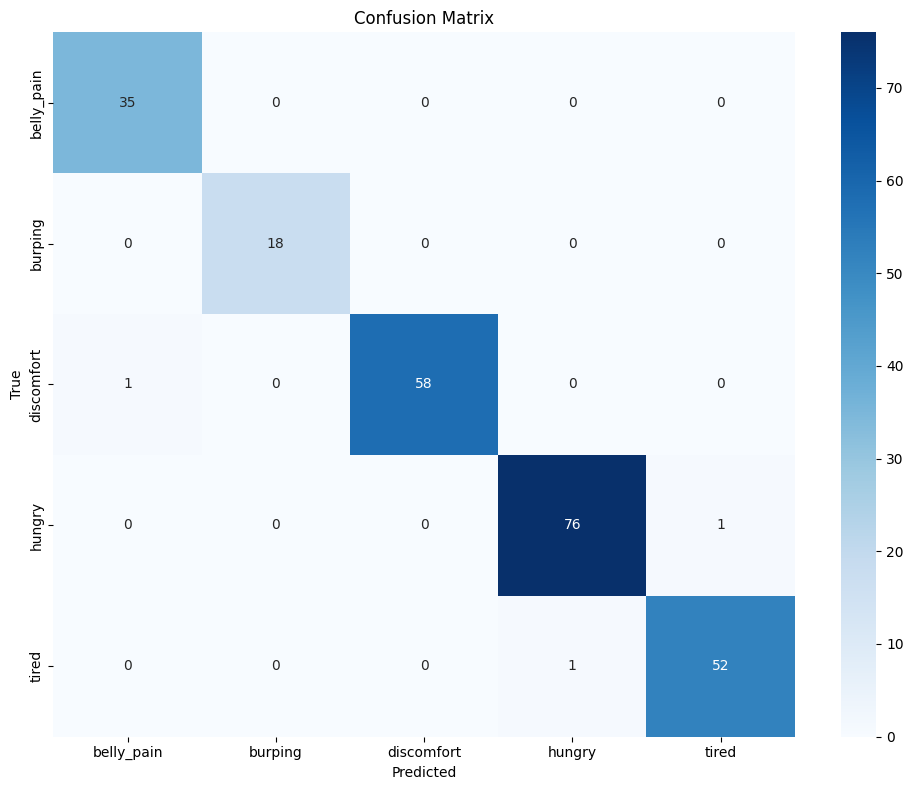

C:\Users\visha\AppData\Local\Temp\ipykernel_8936\719529761.py:309: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(top_importance), y=list(top_features), palette="viridis")


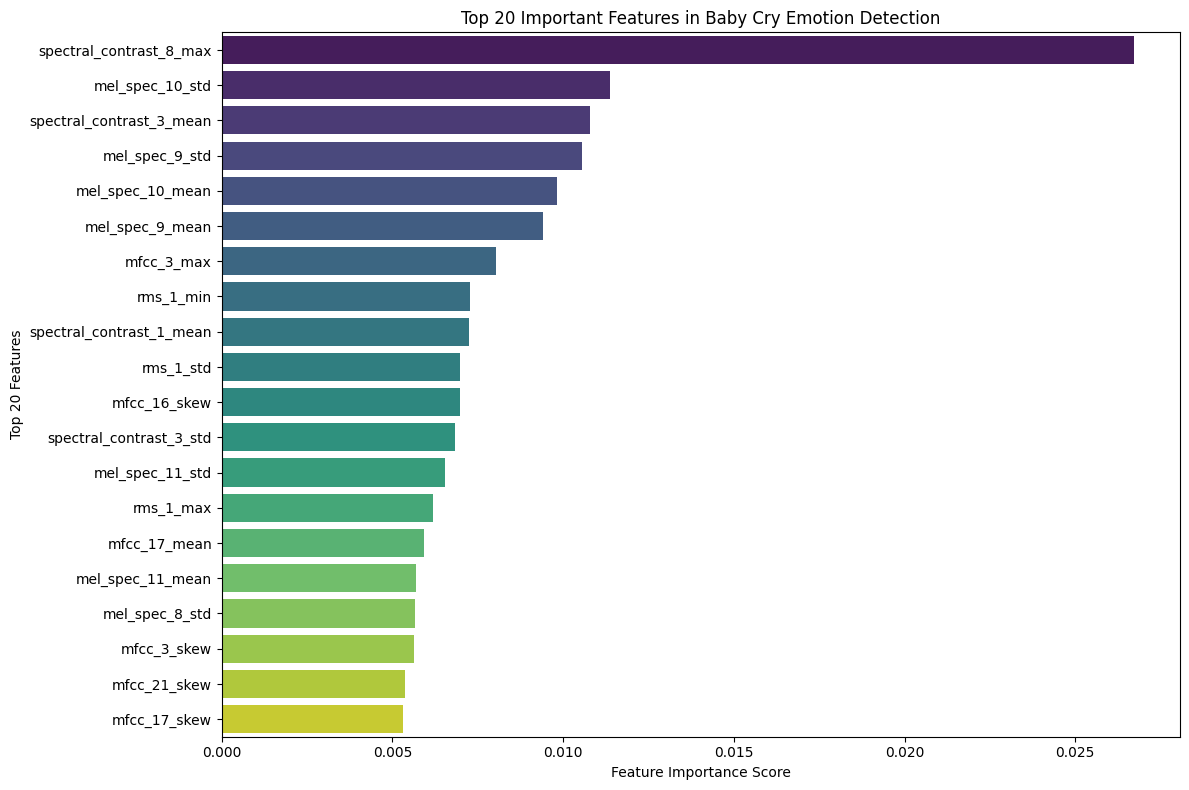


Top 20 Important Features:
spectral_contrast_8_max: 0.0267
mel_spec_10_std: 0.0114
spectral_contrast_3_mean: 0.0108
mel_spec_9_std: 0.0106
mel_spec_10_mean: 0.0098
mel_spec_9_mean: 0.0094
mfcc_3_max: 0.0080
rms_1_min: 0.0073
spectral_contrast_1_mean: 0.0072
rms_1_std: 0.0070
mfcc_16_skew: 0.0070
spectral_contrast_3_std: 0.0068
mel_spec_11_std: 0.0065
rms_1_max: 0.0062
mfcc_17_mean: 0.0059
mel_spec_11_mean: 0.0057
mel_spec_8_std: 0.0056
mfcc_3_skew: 0.0056
mfcc_21_skew: 0.0054
mfcc_17_skew: 0.0053
Model saved as 'baby_cry_model2.pkl


In [8]:
import os
import numpy as np
import librosa
import scipy.signal as signal
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix
import time
import random
from imblearn.over_sampling import SMOTE
from collections import Counter
from scipy.stats import skew, kurtosis

SEED = 12345  # You can change this to any integer you want
np.random.seed(SEED)
random.seed(SEED)

# **Pre-emphasis Function**
def pre_emphasis(signal, alpha=0.97):
    return np.append(signal[0], signal[1:] - alpha * signal[:-1])

# **Bandpass Filter Function (142.91 Hz - 6620.12 Hz)**
def bandpass_filter(y, sr=16000, lowcut=142.91, highcut=6620.12, order=5):
    nyquist = 0.5 * sr
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = signal.butter(order, [low, high], btype='band')
    return signal.filtfilt(b, a, y)


def extract_features(audio_data, sr=16000, n_mfcc=40, n_fft=1024, hop_length=160, win_length=400, window='hann',
                     n_chroma=12, n_mels=13, n_bands=7, fmin=100, bins_per_octave=12, tempogram_win=384, spectral_roll_percent=0.95):
    try:
        # Apply Pre-emphasis
        y = pre_emphasis(audio_data, alpha=0.97)

        # Apply Bandpass Filter
        y = bandpass_filter(y, sr=sr)

        # Zero Crossing Rate & RMS
        zcr = librosa.feature.zero_crossing_rate(y, frame_length=win_length, hop_length=hop_length)
        rms = librosa.feature.rms(y=y, frame_length=win_length, hop_length=hop_length)

        # STFT and Spectral Features
        stft = np.abs(librosa.stft(y, n_fft=n_fft, hop_length=hop_length, win_length=win_length))
        S, phase = librosa.magphase(stft)

        # MFCC and Deltas
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc, n_fft=n_fft, hop_length=hop_length,
                                   win_length=win_length, window=window)
        mfcc_delta = librosa.feature.delta(mfcc)
        mfcc_delta2 = librosa.feature.delta(mfcc, order=2)

        # Advanced Spectral Features
        spectral_centroid = librosa.feature.spectral_centroid(S=S, sr=sr)
        spectral_bandwidth = librosa.feature.spectral_bandwidth(S=S, sr=sr)
        spectral_rolloff = librosa.feature.spectral_rolloff(S=S, sr=sr, roll_percent=spectral_roll_percent)
        spectral_contrast = librosa.feature.spectral_contrast(S=S, sr=sr, n_bands=n_bands, fmin=fmin)
        chroma = librosa.feature.chroma_stft(S=S, sr=sr, n_chroma=n_chroma)
        mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length,
                                                 win_length=win_length, n_mels=n_mels)
        tonnetz = librosa.feature.tonnetz(y=y, sr=sr)

        # Temporal Features

        # Feature aggregation with statistics
        feature_functions = [
            (mfcc, 'mfcc', ['mean', 'std', 'skew', 'max', 'min']),
            (mfcc_delta, 'mfcc_delta', ['mean', 'std']),
            (mfcc_delta2, 'mfcc_delta2', ['mean', 'std']),
            (zcr, 'zcr', ['mean', 'std', 'max']),
            (rms, 'rms', ['mean', 'std', 'max', 'min']),
            (spectral_centroid, 'spectral_centroid', ['mean', 'std', 'max']),
            (spectral_bandwidth, 'spectral_bandwidth', ['mean', 'std', 'max']),
            (spectral_rolloff, 'spectral_rolloff', ['mean', 'std']),
            (spectral_contrast, 'spectral_contrast', ['mean', 'std', 'max']),
            (chroma, 'chroma', ['mean', 'std']),
            (mel_spec, 'mel_spec', ['mean', 'std']),
            (tonnetz, 'tonnetz', ['mean', 'std']),
        ]

        features = []
        feature_names = []

        for feat, feat_name, stats in feature_functions:
            for i in range(feat.shape[0]):
                if 'mean' in stats: 
                    features.append(np.mean(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_mean")
                if 'std' in stats: 
                    features.append(np.std(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_std")
                if 'skew' in stats: 
                    features.append(skew(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_skew")
                if 'kurt' in stats: 
                    features.append(kurtosis(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_kurt")
                if 'max' in stats: 
                    features.append(np.max(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_max")
                if 'min' in stats: 
                    features.append(np.min(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_min")

        # Return both features and their names
        return np.array(features), feature_names
    except Exception as e:
        print(f"Error processing audio data: {e}")
        return None, None


# **Data Augmentation Functions**
def time_stretching(y, rate):
    """Time stretching without changing pitch"""
    return librosa.effects.time_stretch(y, rate=rate)

def pitch_shifting(y, sr, n_steps):
    """Pitch shifting without changing tempo"""
    return librosa.effects.pitch_shift(y, sr=sr, n_steps=n_steps)

def add_noise(y, noise_factor=0.005):
    """Add random noise to the audio"""
    noise = np.random.randn(len(y))
    return y + noise_factor * noise

def random_gain(y, min_factor=0.7, max_factor=1.3):
    """Apply random gain to the audio"""
    gain_factor = np.random.uniform(min_factor, max_factor)
    return y * gain_factor

def time_shifting(y, shift_factor=0.2):
    """Shift audio in time (circular shift)"""
    shift_amount = int(len(y) * shift_factor)
    return np.roll(y, shift_amount)

def augment_audio(y, sr):
    """Apply random augmentation technique to audio"""
    augmentation_techniques = [
        lambda: time_stretching(y, rate=np.random.uniform(0.85, 1.15)),
        lambda: pitch_shifting(y, sr, n_steps=np.random.uniform(-2, 2)),
        lambda: add_noise(y, noise_factor=np.random.uniform(0.001, 0.01)),
        lambda: random_gain(y),
        lambda: time_shifting(y, shift_factor=np.random.uniform(0.1, 0.3))
    ]
    
    # Randomly select two augmentation techniques
    chosen_techniques = np.random.choice(len(augmentation_techniques), size=2, replace=False)
    
    augmented_y = y.copy()
    for idx in chosen_techniques:
        augmented_y = augmentation_techniques[idx]()
    
    return augmented_y

# Global variable to store feature names
all_feature_names = []

# **Load Dataset with Augmentation**
path = r"C:\Users\visha\OneDrive\Desktop\SEM6\Speech Processing\datasets\donateacry_corpus"
features = []
labels = []

# Get initial class counts to determine augmentation needed
initial_counts = {}
for label in os.listdir(path):
    file_count = len(os.listdir(os.path.join(path, label)))
    initial_counts[label] = file_count
    
print("Initial class distribution:")
for label, count in initial_counts.items():
    print(f"{label}: {count} samples")

# Find majority class
majority_class_count = max(initial_counts.values())

# **Extract Features with Augmentation**
for label in os.listdir(path):
    print(f"{label} data is loading...")
    label_files = os.listdir(os.path.join(path, label))
    augmentation_factor = int(np.ceil(majority_class_count / len(label_files))) - 1
    
    # Process original files
    for file_name in label_files:
        file_path = os.path.join(path, label, file_name)
        
        # Load audio file
        y, sr = librosa.load(file_path, sr=16000)
        
        # Extract features from original audio
        feature, feature_names = extract_features(y, sr=sr)
        if feature is not None:
            features.append(feature)
            labels.append(label)
            
            # Store feature names only once
            if not all_feature_names and feature_names is not None:
                all_feature_names = feature_names
        
        # Apply augmentation if needed (for minority classes)
        if augmentation_factor > 0:
            for _ in range(min(augmentation_factor, 10)):  # Cap at 10 augmentations per file
                augmented_y = augment_audio(y, sr)
                augmented_feature, _ = extract_features(augmented_y, sr=sr)
                if augmented_feature is not None:
                    features.append(augmented_feature)
                    labels.append(label)
    
    print(f"{label} data loaded with augmentation...")

# Check if feature dimensions are consistent
feature_lengths = [len(f) for f in features]
if len(set(feature_lengths)) > 1:
    print(f"Warning: Inconsistent feature lengths detected: {set(feature_lengths)}")
    # Find the most common length
    from collections import Counter
    most_common_length = Counter(feature_lengths).most_common(1)[0][0]
    
    # Filter to keep only features with the most common length
    valid_indices = [i for i, length in enumerate(feature_lengths) if length == most_common_length]
    features = [features[i] for i in valid_indices]
    labels = [labels[i] for i in valid_indices]
    print(f"Filtered to {len(features)} samples with consistent feature length of {most_common_length}")

# **Convert to NumPy Arrays**
features = np.array(features)
labels = np.array(labels)

# Show class distribution after augmentation
print("\nClass distribution after augmentation:")
for label, count in Counter(labels).items():
    print(f"{label}: {count} samples")

# **Encode Labels**
le = LabelEncoder()
labels = le.fit_transform(labels)

# **Generate Random Seeds**
split_seed = 3225806193
model_seed = 3613533475

# **Print the Seeds Used**
print(f"Train-Test Split Seed: {split_seed}")
print(f"Random Forest Seed: {model_seed}")

# **Split Data**
X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.20, random_state=split_seed, stratify=labels)

# Apply SMOTE for balancing the training data
smote = SMOTE(random_state=model_seed)
X_train, y_train = smote.fit_resample(X_train, y_train)

print(f"Training data shape after SMOTE: {X_train.shape}")
print(f"Number of features: {X_train.shape[1]}")

# **Train Weighted Random Forest Classifier**
start_time = time.time()
rf = RandomForestClassifier(
    n_estimators=500, 
    max_depth=20, 
    class_weight="balanced", 
    random_state=model_seed,
    n_jobs=-1  # Use all available cores
)
rf.fit(X_train, y_train)
runtime = time.time() - start_time

# **Predict**
y_pred = rf.predict(X_test)

# **Evaluate Performance**
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")

# **Print Results**
print(f"Accuracy: {accuracy:.4f}, F1 Score: {f1:.4f}, Recall: {recall:.4f}, Runtime: {runtime:.2f} sec")

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)
class_names = le.classes_

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.savefig('confusion_matrix.png')
plt.show()

# Get feature importances
if len(all_feature_names) == X_train.shape[1]:
    feature_importances = rf.feature_importances_
    feature_importance_dict = dict(zip(all_feature_names, feature_importances))
    
    # **Sort and Get Top 20 Features**
    sorted_features = sorted(feature_importance_dict.items(), key=lambda x: x[1], reverse=True)[:20]
    top_features, top_importance = zip(*sorted_features)
    
    # Print top 20 features with importance sco
    
    # **Plot Feature Importance**
    plt.figure(figsize=(12, 8))
    sns.barplot(x=list(top_importance), y=list(top_features), palette="viridis")
    plt.xlabel("Feature Importance Score")
    plt.ylabel("Top 20 Features")
    plt.title("Top 20 Important Features in Baby Cry Emotion Detection")
    plt.tight_layout()
    plt.savefig('feature_importance.png')
    plt.show()
    
    # Print top 20 features with importance scores
    print("\nTop 20 Important Features:")
    for feature, importance in sorted_features:
        print(f"{feature}: {importance:.4f}")
else:
    print(f"Error: Feature names count ({len(all_feature_names)}) doesn't match feature count ({X_train.shape[1]})")
    # Use generic feature names as fallback
    generic_feature_names = [f"feature_{i}" for i in range(X_train.shape[1])]
    feature_importances = rf.feature_importances_
    feature_importance_dict = dict(zip(generic_feature_names, feature_importances))
    
    # Sort and get top 20
    sorted_features = sorted(feature_importance_dict.items(), key=lambda x: x[1], reverse=True)[:20]
    top_features, top_importance = zip(*sorted_features)
    
    plt.figure(figsize=(12, 8))
    sns.barplot(x=list(top_importance), y=list(top_features), palette="viridis")
    plt.xlabel("Feature Importance Score")
    plt.ylabel("Top 20 Features")
    plt.title("Top 20 Important Features in Baby Cry Emotion Detection")
    plt.tight_layout()
    plt.savefig('feature_importance.png')
    plt.show()

# Save the model and feature names for future use
import pickle
model_info = {
    'model': rf,
    'feature_names': all_feature_names,
    'class_names': class_names,
    'performance': {
        'accuracy': accuracy,
        'f1': f1,
        'recall': recall
    }
}

with open('baby_cry_model2.pkl', 'wb') as f:
    pickle.dump(model_info, f)

print("Model saved as 'baby_cry_model2.pkl")

Initial class distribution:
belly_pain: 16 samples
burping: 8 samples
discomfort: 27 samples
hungry: 382 samples
tired: 24 samples
belly_pain data is loading...
belly_pain data loaded with augmentation...
burping data is loading...
burping data loaded with augmentation...
discomfort data is loading...
discomfort data loaded with augmentation...
hungry data is loading...
hungry data loaded with augmentation...
tired data is loading...
tired data loaded with augmentation...

Class distribution after augmentation:
belly_pain: 176 samples
burping: 88 samples
discomfort: 297 samples
hungry: 382 samples
tired: 264 samples
Train-Test Split Seed: 3225806193
Random Forest Seed: 3613533475


c:\Users\visha\OneDrive\Desktop\data\myenv\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


Training data shape after SMOTE: (1525, 461)
Number of features: 461
Accuracy: 0.9876, F1 Score: 0.9876, Recall: 0.9876, Runtime: 1.86 sec


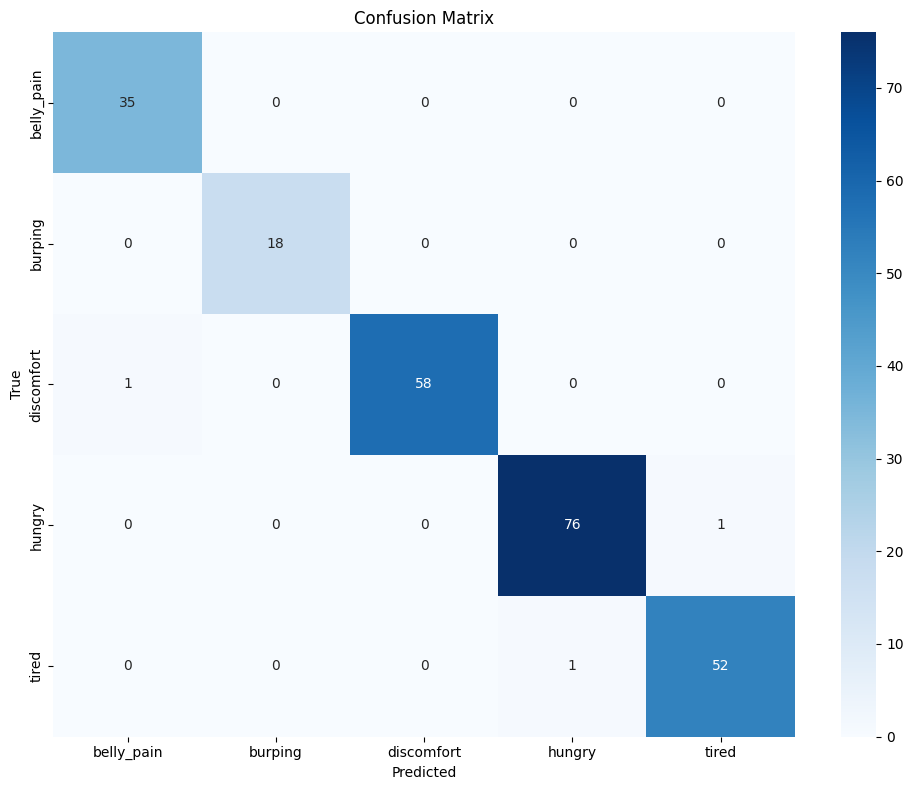

C:\Users\visha\AppData\Local\Temp\ipykernel_48556\719529761.py:309: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(top_importance), y=list(top_features), palette="viridis")


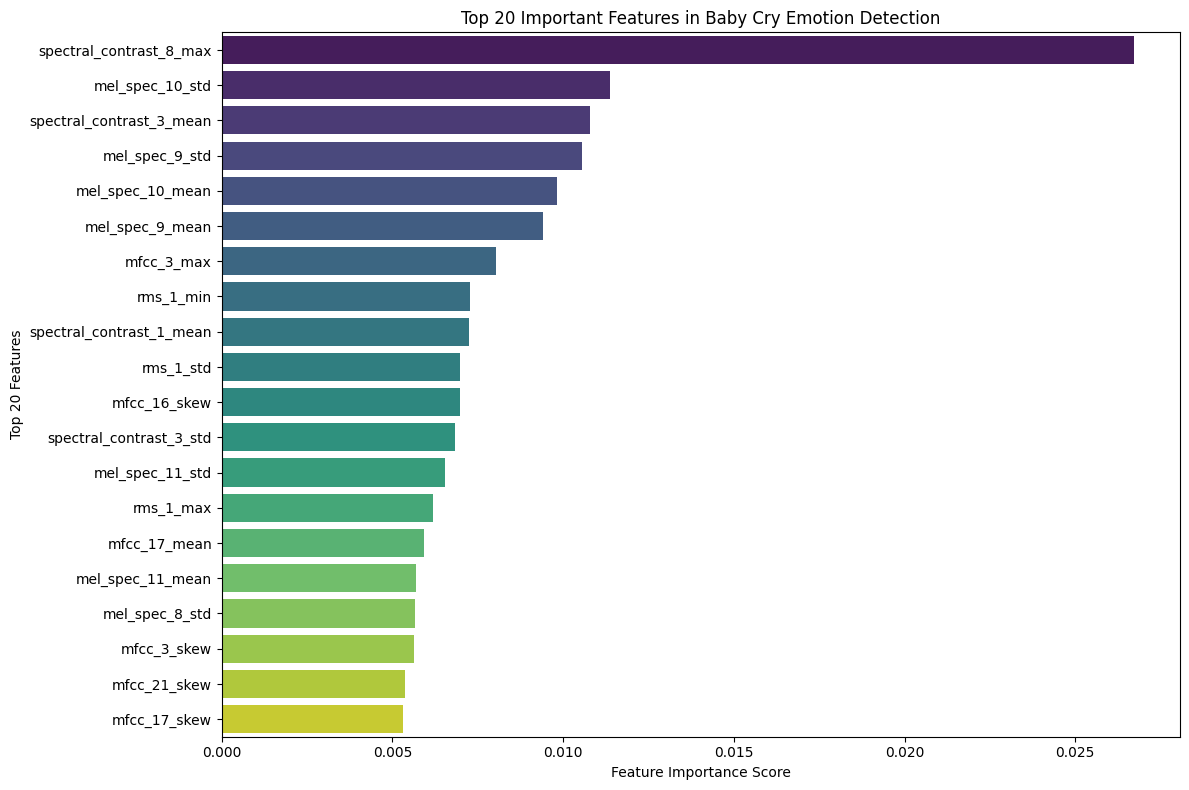


Top 20 Important Features:
spectral_contrast_8_max: 0.0267
mel_spec_10_std: 0.0114
spectral_contrast_3_mean: 0.0108
mel_spec_9_std: 0.0106
mel_spec_10_mean: 0.0098
mel_spec_9_mean: 0.0094
mfcc_3_max: 0.0080
rms_1_min: 0.0073
spectral_contrast_1_mean: 0.0072
rms_1_std: 0.0070
mfcc_16_skew: 0.0070
spectral_contrast_3_std: 0.0068
mel_spec_11_std: 0.0065
rms_1_max: 0.0062
mfcc_17_mean: 0.0059
mel_spec_11_mean: 0.0057
mel_spec_8_std: 0.0056
mfcc_3_skew: 0.0056
mfcc_21_skew: 0.0054
mfcc_17_skew: 0.0053
Model saved as 'baby_cry_model2.pkl


In [ ]:
import os
import numpy as np
import librosa
import scipy.signal as signal
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix
import time
import random
from imblearn.over_sampling import SMOTE
from collections import Counter
from scipy.stats import skew, kurtosis

SEED = 12345  # You can change this to any integer you want
np.random.seed(SEED)
random.seed(SEED)

# **Pre-emphasis Function**
def pre_emphasis(signal, alpha=0.97):
    return np.append(signal[0], signal[1:] - alpha * signal[:-1])

# **Bandpass Filter Function (142.91 Hz - 6620.12 Hz)**
def bandpass_filter(y, sr=16000, lowcut=142.91, highcut=6620.12, order=5):
    nyquist = 0.5 * sr
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = signal.butter(order, [low, high], btype='band')
    return signal.filtfilt(b, a, y)


def extract_features(audio_data, sr=16000, n_mfcc=40, n_fft=1024, hop_length=160, win_length=400, window='hann',
                     n_chroma=12, n_mels=13, n_bands=7, fmin=100, bins_per_octave=12, tempogram_win=384, spectral_roll_percent=0.95):
    try:
        # Apply Pre-emphasis
        y = pre_emphasis(audio_data, alpha=0.97)

        # Apply Bandpass Filter
        y = bandpass_filter(y, sr=sr)

        # Zero Crossing Rate & RMS
        zcr = librosa.feature.zero_crossing_rate(y, frame_length=win_length, hop_length=hop_length)
        rms = librosa.feature.rms(y=y, frame_length=win_length, hop_length=hop_length)

        # STFT and Spectral Features
        stft = np.abs(librosa.stft(y, n_fft=n_fft, hop_length=hop_length, win_length=win_length))
        S, phase = librosa.magphase(stft)

        # MFCC and Deltas
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc, n_fft=n_fft, hop_length=hop_length,
                                   win_length=win_length, window=window)
        mfcc_delta = librosa.feature.delta(mfcc)
        mfcc_delta2 = librosa.feature.delta(mfcc, order=2)

        # Advanced Spectral Features
        spectral_centroid = librosa.feature.spectral_centroid(S=S, sr=sr)
        spectral_bandwidth = librosa.feature.spectral_bandwidth(S=S, sr=sr)
        spectral_rolloff = librosa.feature.spectral_rolloff(S=S, sr=sr, roll_percent=spectral_roll_percent)
        spectral_contrast = librosa.feature.spectral_contrast(S=S, sr=sr, n_bands=n_bands, fmin=fmin)
        chroma = librosa.feature.chroma_stft(S=S, sr=sr, n_chroma=n_chroma)
        mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length,
                                                 win_length=win_length, n_mels=n_mels)
        tonnetz = librosa.feature.tonnetz(y=y, sr=sr)

        # Temporal Features

        # Feature aggregation with statistics
        feature_functions = [
            (mfcc, 'mfcc', ['mean', 'std', 'skew', 'max', 'min']),
            (mfcc_delta, 'mfcc_delta', ['mean', 'std']),
            (mfcc_delta2, 'mfcc_delta2', ['mean', 'std']),
            (zcr, 'zcr', ['mean', 'std', 'max']),
            (rms, 'rms', ['mean', 'std', 'max', 'min']),
            (spectral_centroid, 'spectral_centroid', ['mean', 'std', 'max']),
            (spectral_bandwidth, 'spectral_bandwidth', ['mean', 'std', 'max']),
            (spectral_rolloff, 'spectral_rolloff', ['mean', 'std']),
            (spectral_contrast, 'spectral_contrast', ['mean', 'std', 'max']),
            (chroma, 'chroma', ['mean', 'std']),
            (mel_spec, 'mel_spec', ['mean', 'std']),
            (tonnetz, 'tonnetz', ['mean', 'std']),
        ]

        features = []
        feature_names = []

        for feat, feat_name, stats in feature_functions:
            for i in range(feat.shape[0]):
                if 'mean' in stats: 
                    features.append(np.mean(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_mean")
                if 'std' in stats: 
                    features.append(np.std(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_std")
                if 'skew' in stats: 
                    features.append(skew(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_skew")
                if 'kurt' in stats: 
                    features.append(kurtosis(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_kurt")
                if 'max' in stats: 
                    features.append(np.max(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_max")
                if 'min' in stats: 
                    features.append(np.min(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_min")

        # Return both features and their names
        return np.array(features), feature_names
    except Exception as e:
        print(f"Error processing audio data: {e}")
        return None, None


# **Data Augmentation Functions**
def time_stretching(y, rate):
    """Time stretching without changing pitch"""
    return librosa.effects.time_stretch(y, rate=rate)

def pitch_shifting(y, sr, n_steps):
    """Pitch shifting without changing tempo"""
    return librosa.effects.pitch_shift(y, sr=sr, n_steps=n_steps)

def add_noise(y, noise_factor=0.005):
    """Add random noise to the audio"""
    noise = np.random.randn(len(y))
    return y + noise_factor * noise

def random_gain(y, min_factor=0.7, max_factor=1.3):
    """Apply random gain to the audio"""
    gain_factor = np.random.uniform(min_factor, max_factor)
    return y * gain_factor

def time_shifting(y, shift_factor=0.2):
    """Shift audio in time (circular shift)"""
    shift_amount = int(len(y) * shift_factor)
    return np.roll(y, shift_amount)

def augment_audio(y, sr):
    """Apply random augmentation technique to audio"""
    augmentation_techniques = [
        lambda: time_stretching(y, rate=np.random.uniform(0.85, 1.15)),
        lambda: pitch_shifting(y, sr, n_steps=np.random.uniform(-2, 2)),
        lambda: add_noise(y, noise_factor=np.random.uniform(0.001, 0.01)),
        lambda: random_gain(y),
        lambda: time_shifting(y, shift_factor=np.random.uniform(0.1, 0.3))
    ]
    
    # Randomly select two augmentation techniques
    chosen_techniques = np.random.choice(len(augmentation_techniques), size=2, replace=False)
    
    augmented_y = y.copy()
    for idx in chosen_techniques:
        augmented_y = augmentation_techniques[idx]()
    
    return augmented_y

# Global variable to store feature names
all_feature_names = []

# **Load Dataset with Augmentation**
path = r"C:\Users\visha\OneDrive\Desktop\SEM6\Speech Processing\datasets\donateacry_corpus"
features = []
labels = []

# Get initial class counts to determine augmentation needed
initial_counts = {}
for label in os.listdir(path):
    file_count = len(os.listdir(os.path.join(path, label)))
    initial_counts[label] = file_count
    
print("Initial class distribution:")
for label, count in initial_counts.items():
    print(f"{label}: {count} samples")

# Find majority class
majority_class_count = max(initial_counts.values())

# **Extract Features with Augmentation**
for label in os.listdir(path):
    print(f"{label} data is loading...")
    label_files = os.listdir(os.path.join(path, label))
    augmentation_factor = int(np.ceil(majority_class_count / len(label_files))) - 1
    
    # Process original files
    for file_name in label_files:
        file_path = os.path.join(path, label, file_name)
        
        # Load audio file
        y, sr = librosa.load(file_path, sr=16000)
        
        # Extract features from original audio
        feature, feature_names = extract_features(y, sr=sr)
        if feature is not None:
            features.append(feature)
            labels.append(label)
            
            # Store feature names only once
            if not all_feature_names and feature_names is not None:
                all_feature_names = feature_names
        
        # Apply augmentation if needed (for minority classes)
        if augmentation_factor > 0:
            for _ in range(min(augmentation_factor, 10)):  # Cap at 10 augmentations per file
                augmented_y = augment_audio(y, sr)
                augmented_feature, _ = extract_features(augmented_y, sr=sr)
                if augmented_feature is not None:
                    features.append(augmented_feature)
                    labels.append(label)
    
    print(f"{label} data loaded with augmentation...")

# Check if feature dimensions are consistent
feature_lengths = [len(f) for f in features]
if len(set(feature_lengths)) > 1:
    print(f"Warning: Inconsistent feature lengths detected: {set(feature_lengths)}")
    # Find the most common length
    from collections import Counter
    most_common_length = Counter(feature_lengths).most_common(1)[0][0]
    
    # Filter to keep only features with the most common length
    valid_indices = [i for i, length in enumerate(feature_lengths) if length == most_common_length]
    features = [features[i] for i in valid_indices]
    labels = [labels[i] for i in valid_indices]
    print(f"Filtered to {len(features)} samples with consistent feature length of {most_common_length}")

# **Convert to NumPy Arrays**
features = np.array(features)
labels = np.array(labels)

# Show class distribution after augmentation
print("\nClass distribution after augmentation:")
for label, count in Counter(labels).items():
    print(f"{label}: {count} samples")

# **Encode Labels**
le = LabelEncoder()
labels = le.fit_transform(labels)

# **Generate Random Seeds**
split_seed = 3225806193
model_seed = 3613533475

# **Print the Seeds Used**
print(f"Train-Test Split Seed: {split_seed}")
print(f"Random Forest Seed: {model_seed}")

# **Split Data**
X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.20, random_state=split_seed, stratify=labels)

# Apply SMOTE for balancing the training data
smote = SMOTE(random_state=model_seed)
X_train, y_train = smote.fit_resample(X_train, y_train)


print(f"Training data shape after SMOTE: {X_train.shape}")
print(f"Number of features: {X_train.shape[1]}")


# **Train Weighted Random Forest Classifier**
start_time = time.time()
rf = RandomForestClassifier(
    n_estimators=500, 
    max_depth=20, 
    class_weight="balanced", 
    random_state=model_seed,
    n_jobs=-1  # Use all available cores
)
rf.fit(X_train, y_train)
runtime = time.time() - start_time

# **Predict**
y_pred = rf.predict(X_test)

# **Evaluate Performance**
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")

# **Print Results**
print(f"Accuracy: {accuracy:.4f}, F1 Score: {f1:.4f}, Recall: {recall:.4f}, Runtime: {runtime:.2f} sec")

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)
class_names = le.classes_

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.savefig('confusion_matrix.png')
plt.show()

# Get feature importances
if len(all_feature_names) == X_train.shape[1]:
    feature_importances = rf.feature_importances_
    feature_importance_dict = dict(zip(all_feature_names, feature_importances))
    
    # **Sort and Get Top 20 Features**
    sorted_features = sorted(feature_importance_dict.items(), key=lambda x: x[1], reverse=True)[:20]
    top_features, top_importance = zip(*sorted_features)
    
    # Print top 20 features with importance sco
    
    # **Plot Feature Importance**
    plt.figure(figsize=(12, 8))
    sns.barplot(x=list(top_importance), y=list(top_features), palette="viridis")
    plt.xlabel("Feature Importance Score")
    plt.ylabel("Top 20 Features")
    plt.title("Top 20 Important Features in Baby Cry Emotion Detection")
    plt.tight_layout()
    plt.savefig('feature_importance.png')
    plt.show()
    
    # Print top 20 features with importance scores
    print("\nTop 20 Important Features:")
    for feature, importance in sorted_features:
        print(f"{feature}: {importance:.4f}")
else:
    print(f"Error: Feature names count ({len(all_feature_names)}) doesn't match feature count ({X_train.shape[1]})")
    # Use generic feature names as fallback
    generic_feature_names = [f"feature_{i}" for i in range(X_train.shape[1])]
    feature_importances = rf.feature_importances_
    feature_importance_dict = dict(zip(generic_feature_names, feature_importances))
    
    # Sort and get top 20
    sorted_features = sorted(feature_importance_dict.items(), key=lambda x: x[1], reverse=True)[:20]
    top_features, top_importance = zip(*sorted_features)
    
    plt.figure(figsize=(12, 8))
    sns.barplot(x=list(top_importance), y=list(top_features), palette="viridis")
    plt.xlabel("Feature Importance Score")
    plt.ylabel("Top 20 Features")
    plt.title("Top 20 Important Features in Baby Cry Emotion Detection")
    plt.tight_layout()
    plt.savefig('feature_importance.png')
    plt.show()

# Save the model and feature names for future use
import pickle
model_info = {
    'model': rf,
    'feature_names': all_feature_names,
    'class_names': class_names,
    'performance': {
        'accuracy': accuracy,
        'f1': f1,
        'recall': recall
    }
}

with open('baby_cry_model2.pkl', 'wb') as f:
    pickle.dump(model_info, f)

print("Model saved as 'baby_cry_model2.pkl")

Predicted class: belly_pain
Prediction probabilities:
  belly_pain: 0.9500
  burping: 0.0000
  discomfort: 0.0100
  hungry: 0.0360
  tired: 0.0040


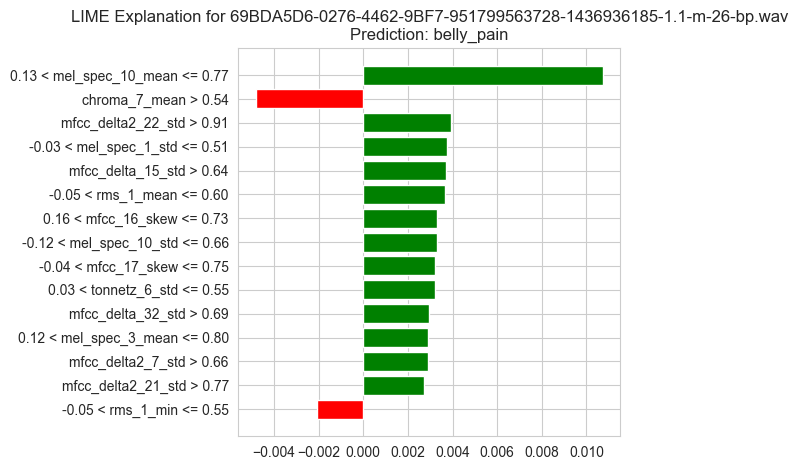

To use this code, uncomment and customize one of the examples above with your file paths.


In [5]:
import numpy as np
import lime
import lime.lime_tabular
import matplotlib.pyplot as plt
import pickle
import os
import librosa
from sklearn.pipeline import make_pipeline
import pandas as pd
# Assuming your extract_features function is in a separate file
import os
import numpy as np
import librosa
import scipy.signal as signal
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix
import time
import random
from imblearn.over_sampling import SMOTE
from collections import Counter
from scipy.stats import skew, kurtosis
import os
import numpy as np
import matplotlib.pyplot as plt
import librosa
import seaborn as sns
from matplotlib.gridspec import GridSpec

SEED = 12345  # You can change this to any integer you want
np.random.seed(SEED)
random.seed(SEED)

# **Pre-emphasis Function**
def pre_emphasis(signal, alpha=0.97):
    return np.append(signal[0], signal[1:] - alpha * signal[:-1])

# **Bandpass Filter Function (142.91 Hz - 6620.12 Hz)**
def bandpass_filter(y, sr=16000, lowcut=142.91, highcut=6620.12, order=5):
    nyquist = 0.5 * sr
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = signal.butter(order, [low, high], btype='band')
    return signal.filtfilt(b, a, y)


def extract_features(audio_data, sr=16000, n_mfcc=40, n_fft=1024, hop_length=160, win_length=400, window='hann',
                     n_chroma=12, n_mels=13, n_bands=7, fmin=100, bins_per_octave=12, tempogram_win=384, spectral_roll_percent=0.95):
    try:
        # Apply Pre-emphasis
        y = pre_emphasis(audio_data, alpha=0.97)

        # Apply Bandpass Filter
        y = bandpass_filter(y, sr=sr)

        # Zero Crossing Rate & RMS
        zcr = librosa.feature.zero_crossing_rate(y, frame_length=win_length, hop_length=hop_length)
        rms = librosa.feature.rms(y=y, frame_length=win_length, hop_length=hop_length)

        # STFT and Spectral Features
        stft = np.abs(librosa.stft(y, n_fft=n_fft, hop_length=hop_length, win_length=win_length))
        S, phase = librosa.magphase(stft)

        # MFCC and Deltas
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc, n_fft=n_fft, hop_length=hop_length,
                                   win_length=win_length, window=window)
        mfcc_delta = librosa.feature.delta(mfcc)
        mfcc_delta2 = librosa.feature.delta(mfcc, order=2)

        # Advanced Spectral Features
        spectral_centroid = librosa.feature.spectral_centroid(S=S, sr=sr)
        spectral_bandwidth = librosa.feature.spectral_bandwidth(S=S, sr=sr)
        spectral_rolloff = librosa.feature.spectral_rolloff(S=S, sr=sr, roll_percent=spectral_roll_percent)
        spectral_contrast = librosa.feature.spectral_contrast(S=S, sr=sr, n_bands=n_bands, fmin=fmin)
        chroma = librosa.feature.chroma_stft(S=S, sr=sr, n_chroma=n_chroma)
        mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length,
                                                 win_length=win_length, n_mels=n_mels)
        tonnetz = librosa.feature.tonnetz(y=y, sr=sr)

        # Temporal Features

        # Feature aggregation with statistics
        feature_functions = [
            (mfcc, 'mfcc', ['mean', 'std', 'skew', 'max', 'min']),
            (mfcc_delta, 'mfcc_delta', ['mean', 'std']),
            (mfcc_delta2, 'mfcc_delta2', ['mean', 'std']),
            (zcr, 'zcr', ['mean', 'std', 'max']),
            (rms, 'rms', ['mean', 'std', 'max', 'min']),
            (spectral_centroid, 'spectral_centroid', ['mean', 'std', 'max']),
            (spectral_bandwidth, 'spectral_bandwidth', ['mean', 'std', 'max']),
            (spectral_rolloff, 'spectral_rolloff', ['mean', 'std']),
            (spectral_contrast, 'spectral_contrast', ['mean', 'std', 'max']),
            (chroma, 'chroma', ['mean', 'std']),
            (mel_spec, 'mel_spec', ['mean', 'std']),
            (tonnetz, 'tonnetz', ['mean', 'std']),
        ]

        features = []
        feature_names = []

        for feat, feat_name, stats in feature_functions:
            for i in range(feat.shape[0]):
                if 'mean' in stats: 
                    features.append(np.mean(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_mean")
                if 'std' in stats: 
                    features.append(np.std(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_std")
                if 'skew' in stats: 
                    features.append(skew(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_skew")
                if 'kurt' in stats: 
                    features.append(kurtosis(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_kurt")
                if 'max' in stats: 
                    features.append(np.max(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_max")
                if 'min' in stats: 
                    features.append(np.min(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_min")

        # Return both features and their names
        return np.array(features), feature_names
    except Exception as e:
        print(f"Error processing audio data: {e}")
        return None, None
# Load the trained model and necessary information
with open('baby_cry_model2.pkl', 'rb') as f:
    model_info = pickle.load(f)

rf_model = model_info['model']
feature_names = model_info['feature_names']
class_names = model_info['class_names']

# Create a LIME explainer
explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=np.random.normal(0, 1, (100, len(feature_names))),  # Generate dummy data for initialization
    feature_names=feature_names,
    class_names=class_names,
    mode='classification',
    discretize_continuous=True,
    random_state=12345
)

def explain_prediction(audio_path, num_features=10, save_plot=True, plot_filename='lime_explanation.png'):
    """
    Explain a prediction for a specific audio file using LIME
    
    Parameters:
    -----------
    audio_path : str
        Path to the audio file to explain
    num_features : int
        Number of top features to show in the explanation
    save_plot : bool
        Whether to save the explanation plot
    plot_filename : str
        Filename to save the plot
        
    Returns:
    --------
    explanation : LimeTabularExplanation
        The LIME explanation object
    """
    # Load and preprocess the audio file
    y, sr = librosa.load(audio_path, sr=16000)
    
    # Extract features using the same function as in training
    features, _ = extract_features(y, sr=sr)
    
    # Ensure it's a 1D array and reshape for LIME
    features = np.array(features).reshape(1, -1)
    
    # Get the prediction
    prediction = rf_model.predict(features)[0]
    prediction_proba = rf_model.predict_proba(features)[0]
    
    # Create an explanation
    explanation = explainer.explain_instance(
        features[0], 
        rf_model.predict_proba,
        num_features=num_features,
        top_labels=3  # Explain top 3 predictions
    )
    
    # Print the prediction and probabilities
    predicted_class = class_names[prediction]
    print(f"Predicted class: {predicted_class}")
    print(f"Prediction probabilities:")
    for i, prob in enumerate(prediction_proba):
        print(f"  {class_names[i]}: {prob:.4f}")
    
    # Show the explanation
    fig = explanation.as_pyplot_figure(label=prediction)
    plt.title(f"LIME Explanation for {os.path.basename(audio_path)}\nPrediction: {predicted_class}")
    plt.tight_layout()
    
    if save_plot:
        plt.savefig(plot_filename, bbox_inches='tight', dpi=300)
    
    plt.show()
    
    # Return the explanation for further analysis if needed
    return explanation

def explain_multiple_samples(audio_folder, num_samples=5, num_features=10):
    """
    Explain predictions for multiple samples from different classes
    
    Parameters:
    -----------
    audio_folder : str
        Path to the folder containing audio samples organized by class folders
    num_samples : int
        Number of samples to explain per class
    num_features : int
        Number of top features to show in each explanation
    """
    for class_folder in os.listdir(audio_folder):
        class_path = os.path.join(audio_folder, class_folder)
        if os.path.isdir(class_path):
            print(f"\nExplaining samples from class: {class_folder}")
            
            # Get all audio files in this class folder
            audio_files = [f for f in os.listdir(class_path) if f.endswith(('.wav', '.mp3'))]
            
            # Select a subset (max num_samples)
            sample_files = audio_files[:min(num_samples, len(audio_files))]
            
            for i, file in enumerate(sample_files):
                file_path = os.path.join(class_path, file)
                print(f"\nSample {i+1}: {file}")
                
                # Create a specific filename for this explanation
                plot_filename = f"lime_{class_folder}_{i+1}.png"
                
                # Generate and save the explanation
                explain_prediction(file_path, num_features=num_features, save_plot=True, plot_filename=plot_filename)

def compare_feature_importance(global_importance_file='feature_importance.png'):
    """
    Compare LIME local explanations with global feature importance
    
    Parameters:
    -----------
    global_importance_file : str
        Path to the global feature importance plot generated by the model
    """
    # This function requires generating explanations for several samples first
    print("To compare local explanations with global feature importance:")
    print("1. First run explain_multiple_samples() to generate local explanations")
    print("2. Then visually compare these with the global feature importance plot")
    print("3. Look for features that are consistently important locally but not globally")
    print("   or vice versa, which can provide insights into your model's behavior")

# Example of how to use these functions
if __name__ == "__main__":


    audio_path = r"C:\Users\visha\OneDrive\Desktop\SEM6\Speech Processing\datasets\donateacry_corpus\belly_pain\69BDA5D6-0276-4462-9BF7-951799563728-1436936185-1.1-m-26-bp.wav"
    explanation = explain_prediction(audio_path, num_features=15)
    
    # Example 2: Explain multip le samples from different classes
    # Replace with the path to your dataset folder
    # audio_folder = "path/to/your/dataset"
    # explain_multiple_samples(audio_folder, num_samples=3, num_features=10)
    
    # Example 3: Compare with global feature importance
    # compare_feature_importance()
    
    print("To use this code, uncomment and customize one of the examples above with your file paths.")

Found 5 class folders: belly_pain, burping, discomfort, hungry, tired

Processing class: belly_pain
Sample file: 549a46d8-9c84-430e-ade8-97eae2bef787-1430130772174-1.7-m-48-bp.wav
Predicted class: belly_pain
Prediction probabilities:
  belly_pain: 0.8080
  burping: 0.0080
  discomfort: 0.0380
  hungry: 0.1220
  tired: 0.0240


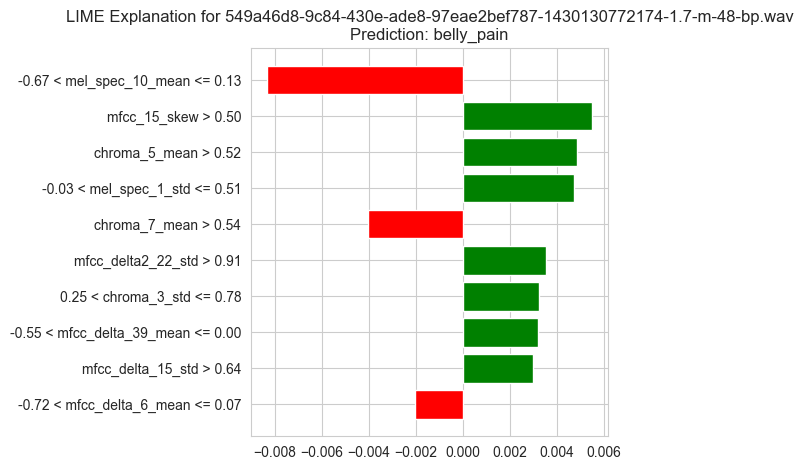

Explanation saved to: C:\Users\visha\OneDrive\Desktop\SEM6\Speech Processing\datasets\donateacry_corpus\lime_explanations\lime_belly_pain_549a46d8-9c84-430e-ade8-97eae2bef787-1430130772174-1.7-m-48-bp.png

Processing class: burping
Sample file: 5afc6a14-a9d8-45f8-b31d-c79dd87cc8c6-1430757039803-1.7-m-48-bu.wav
Predicted class: burping
Prediction probabilities:
  belly_pain: 0.0000
  burping: 0.9940
  discomfort: 0.0020
  hungry: 0.0040
  tired: 0.0000


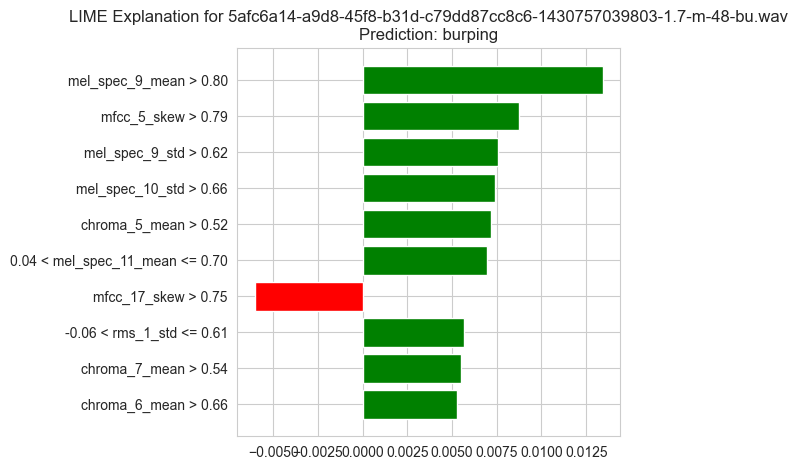

Explanation saved to: C:\Users\visha\OneDrive\Desktop\SEM6\Speech Processing\datasets\donateacry_corpus\lime_explanations\lime_burping_5afc6a14-a9d8-45f8-b31d-c79dd87cc8c6-1430757039803-1.7-m-48-bu.png

Processing class: discomfort
Sample file: 10A40438-09AA-4A21-83B4-8119F03F7A11-1430925142-1.0-f-26-dc.wav
Predicted class: discomfort
Prediction probabilities:
  belly_pain: 0.0060
  burping: 0.0180
  discomfort: 0.8380
  hungry: 0.1260
  tired: 0.0120


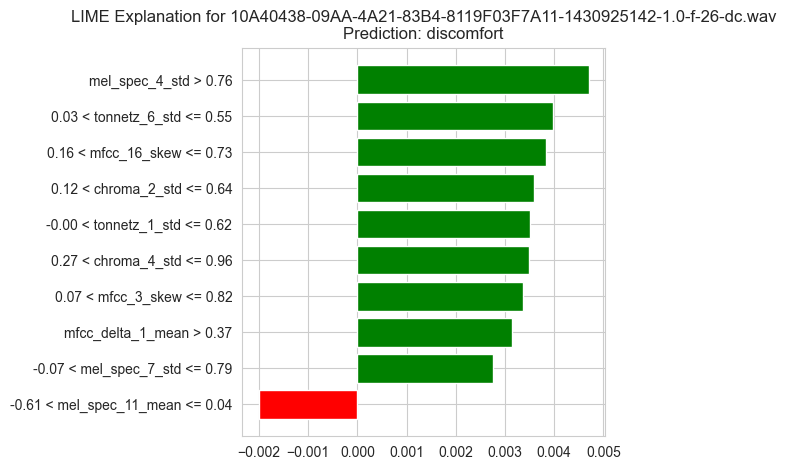

Explanation saved to: C:\Users\visha\OneDrive\Desktop\SEM6\Speech Processing\datasets\donateacry_corpus\lime_explanations\lime_discomfort_10A40438-09AA-4A21-83B4-8119F03F7A11-1430925142-1.0-f-26-dc.png

Processing class: hungry
Sample file: 02c3b725-26e4-4a2c-9336-04ddc58836d9-1430726196216-1.7-m-04-hu.wav
Predicted class: hungry
Prediction probabilities:
  belly_pain: 0.0360
  burping: 0.0080
  discomfort: 0.0620
  hungry: 0.8240
  tired: 0.0700


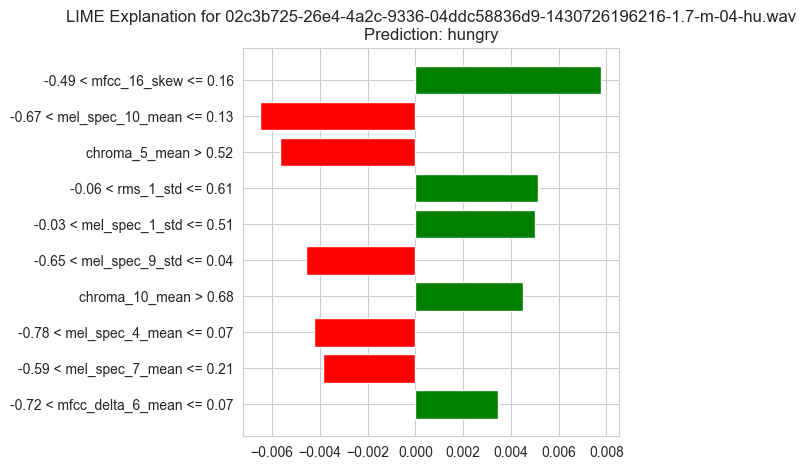

Explanation saved to: C:\Users\visha\OneDrive\Desktop\SEM6\Speech Processing\datasets\donateacry_corpus\lime_explanations\lime_hungry_02c3b725-26e4-4a2c-9336-04ddc58836d9-1430726196216-1.7-m-04-hu.png

Processing class: tired
Sample file: 03ADDCFB-354E-416D-BF32-260CF47F7060-1433658024-1.1-f-04-ti.wav
Predicted class: tired
Prediction probabilities:
  belly_pain: 0.0060
  burping: 0.0000
  discomfort: 0.0060
  hungry: 0.0340
  tired: 0.9540


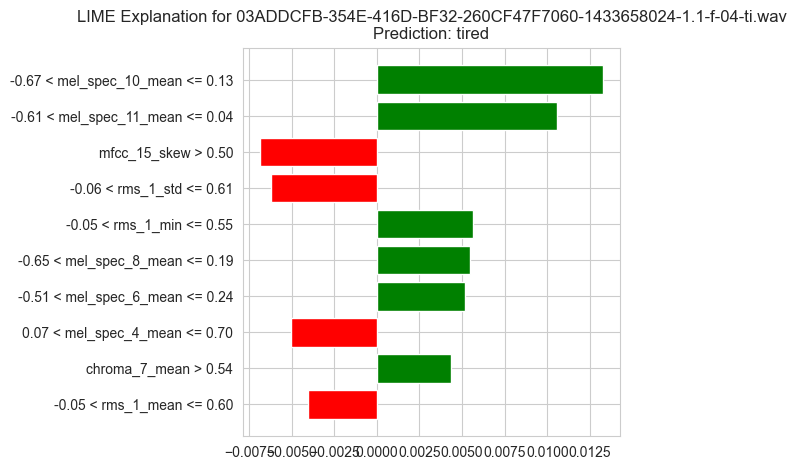

Explanation saved to: C:\Users\visha\OneDrive\Desktop\SEM6\Speech Processing\datasets\donateacry_corpus\lime_explanations\lime_tired_03ADDCFB-354E-416D-BF32-260CF47F7060-1433658024-1.1-f-04-ti.png

All explanations saved to C:\Users\visha\OneDrive\Desktop\SEM6\Speech Processing\datasets\donateacry_corpus\lime_explanations


In [7]:
import os
import numpy as np
import matplotlib.pyplot as plt
import librosa
import seaborn as sns

def explain_prediction(audio_path, num_features=10, save_plot=True, plot_filename='lime_explanation.png'):
    """
    Explain a prediction for a specific audio file using LIME
    
    Parameters:
    -----------
    audio_path : str
        Path to the audio file to explain
    num_features : int
        Number of top features to show in the explanation
    save_plot : bool
        Whether to save the explanation plot
    plot_filename : str
        Filename to save the plot
        
    Returns:
    --------
    explanation : LimeTabularExplanation
        The LIME explanation object
    """
    # Load and preprocess the audio file
    y, sr = librosa.load(audio_path, sr=16000)
    
    # Extract features using the same function as in training
    features, _ = extract_features(y, sr=sr)
    
    # Ensure it's a 1D array and reshape for LIME
    features = np.array(features).reshape(1, -1)
    
    # Get the prediction
    prediction = rf_model.predict(features)[0]
    prediction_proba = rf_model.predict_proba(features)[0]
    
    # Create an explanation
    explanation = explainer.explain_instance(
        features[0], 
        rf_model.predict_proba,
        num_features=num_features,
        top_labels=3  # Explain top 3 predictions
    )
    
    # Print the prediction and probabilities
    predicted_class = class_names[prediction]
    print(f"Predicted class: {predicted_class}")
    print(f"Prediction probabilities:")
    for i, prob in enumerate(prediction_proba):
        print(f"  {class_names[i]}: {prob:.4f}")
    
    # Show the explanation
    fig = explanation.as_pyplot_figure(label=prediction)
    plt.title(f"LIME Explanation for {os.path.basename(audio_path)}\nPrediction: {predicted_class}")
    plt.tight_layout()
    
    if save_plot:
        plt.savefig(plot_filename, bbox_inches='tight', dpi=300)
    
    plt.show()
    
    # Return the explanation for further analysis if needed
    return explanation

def visualize_class_wise_explanations(base_folder):
    """
    Generate LIME explanations for one sample from each class folder
    
    Parameters:
    -----------
    base_folder : str
        Path to the base folder containing class subfolders
    """
    # Get all class folders
    class_folders = [f for f in os.listdir(base_folder) if os.path.isdir(os.path.join(base_folder, f))]
    
    print(f"Found {len(class_folders)} class folders: {', '.join(class_folders)}")
    
    # Create a directory for saving plots if it doesn't exist
    output_dir = os.path.join(base_folder, "lime_explanations")
    os.makedirs(output_dir, exist_ok=True)
    
    # Process one sample from each class
    for class_folder in class_folders:
        class_path = os.path.join(base_folder, class_folder)
        
        # Get the first audio file in this class folder
        audio_files = [f for f in os.listdir(class_path) if f.endswith(('.wav', '.mp3'))]
        
        if not audio_files:
            print(f"No audio files found in {class_folder} folder. Skipping.")
            continue
            
        # Get the first file
        file_path = os.path.join(class_path, audio_files[0])
        file_name = os.path.basename(file_path)
        
        print(f"\nProcessing class: {class_folder}")
        print(f"Sample file: {file_name}")
        
        # Create a specific filename for this explanation
        plot_filename = os.path.join(output_dir, f"lime_{class_folder}_{os.path.splitext(file_name)[0]}.png")
        
        # Generate the explanation using your function
        explanation = explain_prediction(
            file_path, 
            num_features=10, 
            save_plot=True, 
            plot_filename=plot_filename
        )
        
        print(f"Explanation saved to: {plot_filename}")
    
    print(f"\nAll explanations saved to {output_dir}")

# Main execution
if __name__ == "__main__":
    # Path to your dataset
    base_folder = r"C:\Users\visha\OneDrive\Desktop\SEM6\Speech Processing\datasets\donateacry_corpus"
    
    # Generate the LIME explanations
    visualize_class_wise_explanations(base_folder)

Found 7 class folders: belly_pain, burping, discomfort, enhanced_lime_explanations, hungry, lime_explanations, tired

Processing class: belly_pain
Sample file: 549a46d8-9c84-430e-ade8-97eae2bef787-1430130772174-1.7-m-48-bp.wav
Predicted class: belly_pain
Prediction probabilities:
  belly_pain: 0.8080
  burping: 0.0080
  discomfort: 0.0380
  hungry: 0.1220
  tired: 0.0240


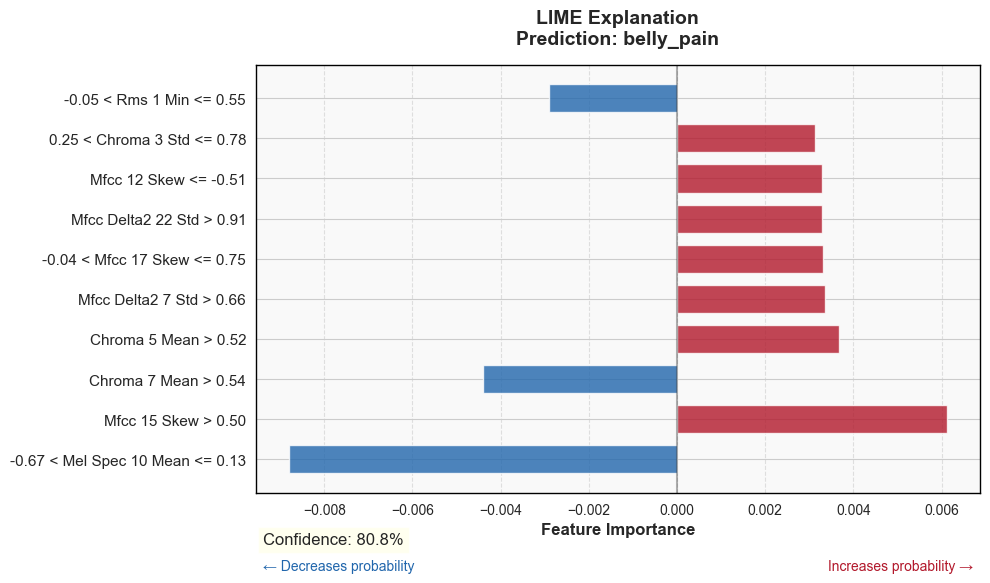

Enhanced explanation saved to: C:\Users\visha\OneDrive\Desktop\SEM6\Speech Processing\datasets\donateacry_corpus\enhanced_lime_explanations\enhanced_lime_belly_pain_549a46d8-9c84-430e-ade8-97eae2bef787-1430130772174-1.7-m-48-bp.png

Processing class: burping
Sample file: 5afc6a14-a9d8-45f8-b31d-c79dd87cc8c6-1430757039803-1.7-m-48-bu.wav
Predicted class: burping
Prediction probabilities:
  belly_pain: 0.0000
  burping: 0.9940
  discomfort: 0.0020
  hungry: 0.0040
  tired: 0.0000


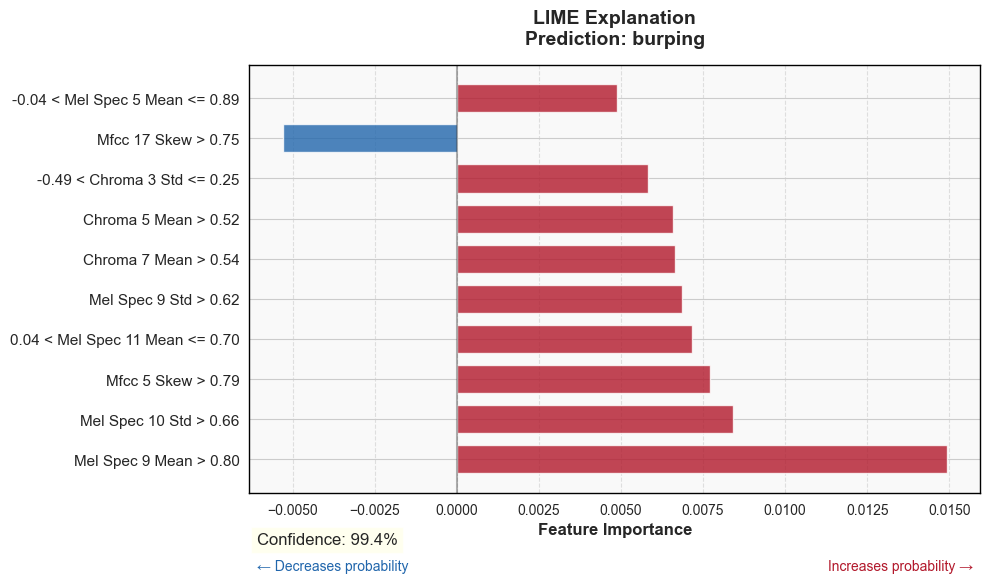

Enhanced explanation saved to: C:\Users\visha\OneDrive\Desktop\SEM6\Speech Processing\datasets\donateacry_corpus\enhanced_lime_explanations\enhanced_lime_burping_5afc6a14-a9d8-45f8-b31d-c79dd87cc8c6-1430757039803-1.7-m-48-bu.png

Processing class: discomfort
Sample file: 10A40438-09AA-4A21-83B4-8119F03F7A11-1430925142-1.0-f-26-dc.wav
Predicted class: discomfort
Prediction probabilities:
  belly_pain: 0.0060
  burping: 0.0180
  discomfort: 0.8380
  hungry: 0.1260
  tired: 0.0120


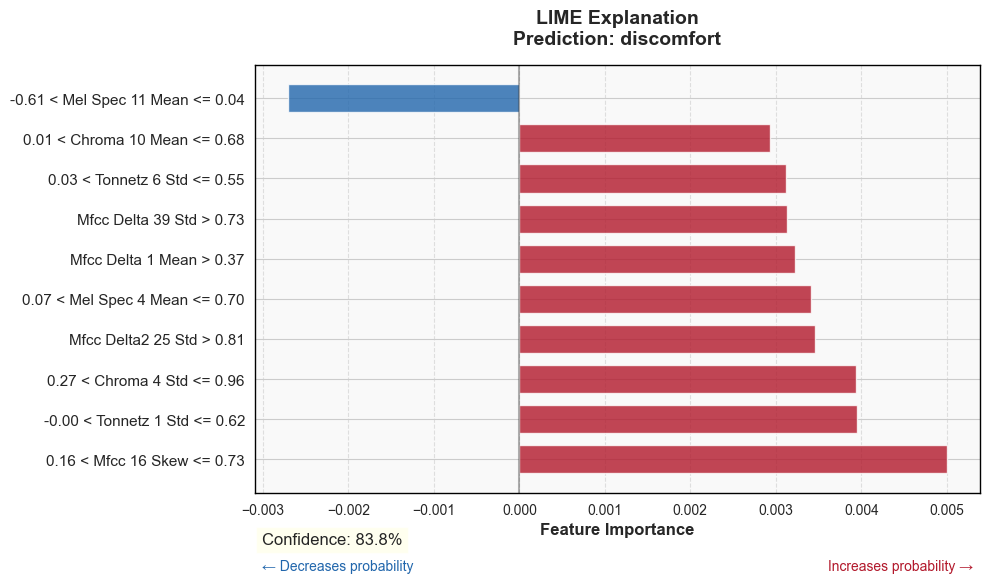

Enhanced explanation saved to: C:\Users\visha\OneDrive\Desktop\SEM6\Speech Processing\datasets\donateacry_corpus\enhanced_lime_explanations\enhanced_lime_discomfort_10A40438-09AA-4A21-83B4-8119F03F7A11-1430925142-1.0-f-26-dc.png
No audio files found in enhanced_lime_explanations folder. Skipping.

Processing class: hungry
Sample file: 02c3b725-26e4-4a2c-9336-04ddc58836d9-1430726196216-1.7-m-04-hu.wav
Predicted class: hungry
Prediction probabilities:
  belly_pain: 0.0360
  burping: 0.0080
  discomfort: 0.0620
  hungry: 0.8240
  tired: 0.0700


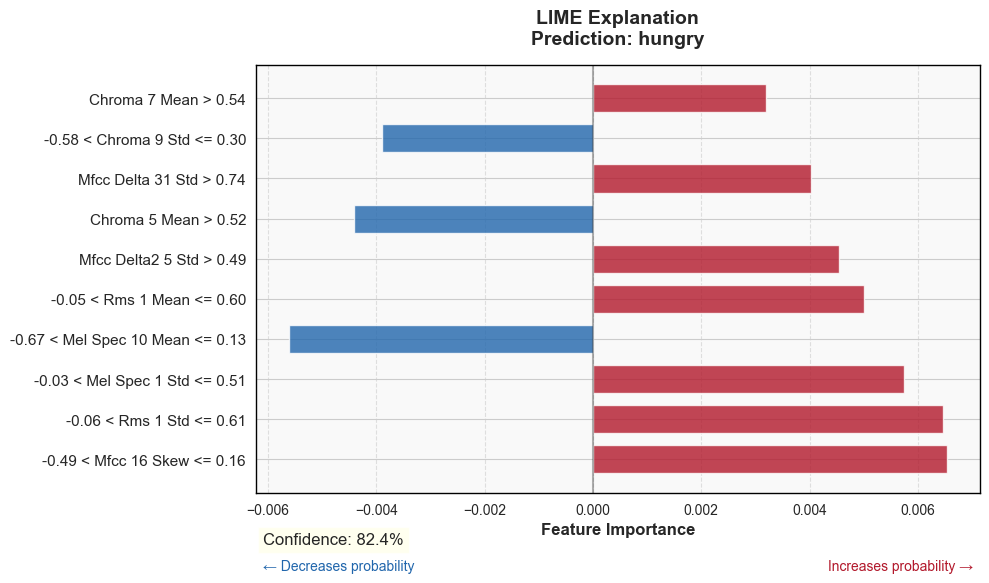

Enhanced explanation saved to: C:\Users\visha\OneDrive\Desktop\SEM6\Speech Processing\datasets\donateacry_corpus\enhanced_lime_explanations\enhanced_lime_hungry_02c3b725-26e4-4a2c-9336-04ddc58836d9-1430726196216-1.7-m-04-hu.png
No audio files found in lime_explanations folder. Skipping.

Processing class: tired
Sample file: 03ADDCFB-354E-416D-BF32-260CF47F7060-1433658024-1.1-f-04-ti.wav
Predicted class: tired
Prediction probabilities:
  belly_pain: 0.0060
  burping: 0.0000
  discomfort: 0.0060
  hungry: 0.0340
  tired: 0.9540


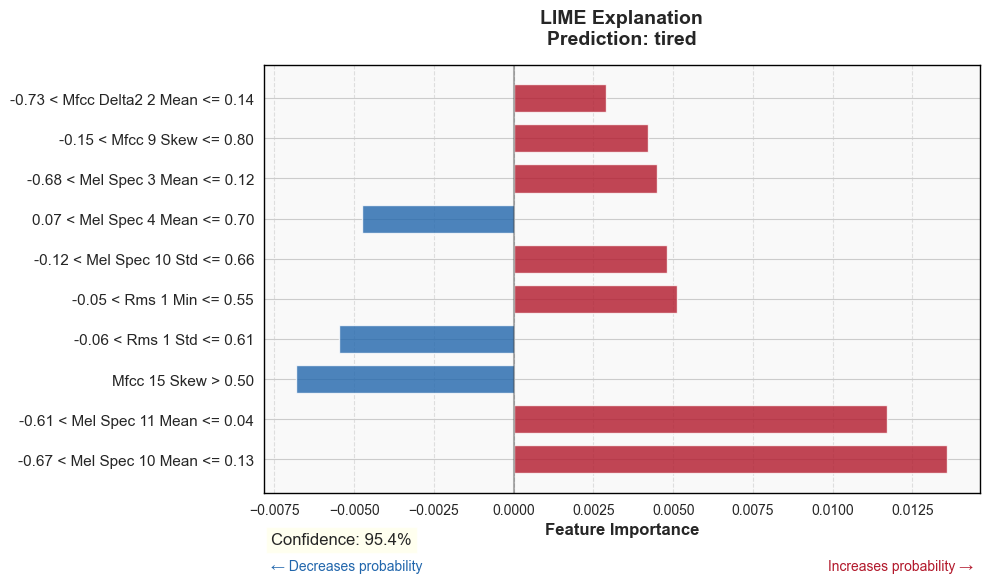

Enhanced explanation saved to: C:\Users\visha\OneDrive\Desktop\SEM6\Speech Processing\datasets\donateacry_corpus\enhanced_lime_explanations\enhanced_lime_tired_03ADDCFB-354E-416D-BF32-260CF47F7060-1433658024-1.1-f-04-ti.png

All enhanced explanations saved to C:\Users\visha\OneDrive\Desktop\SEM6\Speech Processing\datasets\donateacry_corpus\enhanced_lime_explanations


In [10]:
import os
import numpy as np
import matplotlib.pyplot as plt
import librosa
import seaborn as sns

def explain_prediction(audio_path, num_features=10, save_plot=True, plot_filename='lime_explanation.png'):
    """
    Explain a prediction for a specific audio file using LIME
    
    Parameters:
    -----------
    audio_path : str
        Path to the audio file to explain
    num_features : int
        Number of top features to show in the explanation
    save_plot : bool
        Whether to save the explanation plot
    plot_filename : str
        Filename to save the plot
        
    Returns:
    --------
    explanation : LimeTabularExplanation
        The LIME explanation object
    """
    # Load and preprocess the audio file
    y, sr = librosa.load(audio_path, sr=16000)
    
    # Extract features using the same function as in training
    features, _ = extract_features(y, sr=sr)
    
    # Ensure it's a 1D array and reshape for LIME
    features = np.array(features).reshape(1, -1)
    
    # Get the prediction
    prediction = rf_model.predict(features)[0]
    prediction_proba = rf_model.predict_proba(features)[0]
    
    # Create an explanation
    explanation = explainer.explain_instance(
        features[0], 
        rf_model.predict_proba,
        num_features=num_features,
        top_labels=3  # Explain top 3 predictions
    )
    
    # Print the prediction and probabilities
    predicted_class = class_names[prediction]
    print(f"Predicted class: {predicted_class}")
    print(f"Prediction probabilities:")
    for i, prob in enumerate(prediction_proba):
        print(f"  {class_names[i]}: {prob:.4f}")
    
    # Show the explanation
    fig = explanation.as_pyplot_figure(label=prediction)
    plt.title(f"LIME Explanation for {os.path.basename(audio_path)}\nPrediction: {predicted_class}")
    plt.tight_layout()
    
    if save_plot:
        plt.savefig(plot_filename, bbox_inches='tight', dpi=300)
    
    plt.show()
    
    # Return the explanation for further analysis if needed
    return explanation

def enhanced_explanation_plot(audio_path, num_features=10, save_plot=True, plot_filename='enhanced_lime_explanation.png'):
    """
    Create an enhanced version of LIME explanation plot
    
    Parameters:
    -----------
    audio_path : str
        Path to the audio file to explain
    num_features : int
        Number of top features to show in the explanation
    save_plot : bool
        Whether to save the explanation plot
    plot_filename : str
        Filename to save the plot
        
    Returns:
    --------
    explanation : LimeTabularExplanation
        The LIME explanation object
    """
    # Get the explanation using the original function (but don't save or show its plot)
    # Load and preprocess the audio file
    y, sr = librosa.load(audio_path, sr=16000)
    
    # Extract features using the same function as in training
    features, _ = extract_features(y, sr=sr)
    
    # Ensure it's a 1D array and reshape for LIME
    features = np.array(features).reshape(1, -1)
    
    # Get the prediction
    prediction = rf_model.predict(features)[0]
    prediction_proba = rf_model.predict_proba(features)[0]
    
    # Create an explanation
    explanation = explainer.explain_instance(
        features[0], 
        rf_model.predict_proba,
        num_features=num_features,
        top_labels=3  # Explain top 3 predictions
    )
    
    # Print the prediction and probabilities
    predicted_class = class_names[prediction]
    print(f"Predicted class: {predicted_class}")
    print(f"Prediction probabilities:")
    for i, prob in enumerate(prediction_proba):
        print(f"  {class_names[i]}: {prob:.4f}")
    
    # Now create our enhanced plot
    # Set the style
    sns.set_style("whitegrid")
    
    # Create the figure
    plt.figure(figsize=(10, 6))
    
    # Get explanation data for the top prediction
    exp = explanation.as_list(label=prediction)
    features = [x[0] for x in exp]
    values = [x[1] for x in exp]
    
    # Create color map based on positive/negative values
    colors = ['#2166AC' if x < 0 else '#B2182B' for x in values]
    
    # Create horizontal bar chart
    y_pos = np.arange(len(features))
    plt.barh(y_pos, values, color=colors, height=0.7, alpha=0.8)
    
    # Add a vertical line at x=0
    plt.axvline(x=0, color='black', linestyle='-', alpha=0.3)
    
    # Set labels and ticks
    plt.yticks(y_pos, [f.split('_')[0] for f in features], fontsize=11)
    
    # Format the feature names for better readability
    plt.yticks(y_pos, [f.replace('_', ' ').title() for f in features], fontsize=11)
    
    # Set axis labels and title with improved styling
    plt.xlabel("Feature Importance", fontsize=12, fontweight='bold')
    
    # File info for title
    file_name = os.path.basename(audio_path)
    class_name = os.path.basename(os.path.dirname(audio_path))
    
    # Create a nice title with multiple lines
    plt.title(f"LIME Explanation\nPrediction: {predicted_class}", 
              fontsize=14, fontweight='bold', pad=15)
    
    # Add confidence information
    confidence = prediction_proba[prediction] * 100
    plt.text(0.01, -0.12, f"Confidence: {confidence:.1f}%", transform=plt.gca().transAxes, 
             fontsize=12, bbox=dict(facecolor='lightyellow', alpha=0.5))
    
    # Add legend/annotations for positive/negative impact
    plt.text(0.01, -0.18, "← Decreases probability", transform=plt.gca().transAxes, 
             color='#2166AC', fontsize=10, ha='left')
    plt.text(0.99, -0.18, "Increases probability →", transform=plt.gca().transAxes, 
             color='#B2182B', fontsize=10, ha='right')
    
    # Add grid just for x-axis
    plt.grid(axis='x', linestyle='--', alpha=0.6)
    
    # Add border around the plot
    for spine in plt.gca().spines.values():
        spine.set_visible(True)
        spine.set_color('black')
        spine.set_linewidth(1)
    
    # Improve layout
    plt.tight_layout()
    
    # Add a subtle background color
    plt.gca().set_facecolor('#f9f9f9')
    
    # Save if requested
    if save_plot:
        plt.savefig(plot_filename, bbox_inches='tight', dpi=300)
    
    plt.show()
    
    # Return the explanation for further analysis if needed
    return explanation

def visualize_class_wise_explanations(base_folder):
    """
    Generate enhanced LIME explanations for one sample from each class folder
    
    Parameters:
    -----------
    base_folder : str
        Path to the base folder containing class subfolders
    """
    # Get all class folders
    class_folders = [f for f in os.listdir(base_folder) if os.path.isdir(os.path.join(base_folder, f))]
    
    print(f"Found {len(class_folders)} class folders: {', '.join(class_folders)}")
    
    # Create a directory for saving plots if it doesn't exist
    output_dir = os.path.join(base_folder, "enhanced_lime_explanations")
    os.makedirs(output_dir, exist_ok=True)
    
    # Process one sample from each class
    for class_folder in class_folders:
        class_path = os.path.join(base_folder, class_folder)
        
        # Get the first audio file in this class folder
        audio_files = [f for f in os.listdir(class_path) if f.endswith(('.wav', '.mp3'))]
        
        if not audio_files:
            print(f"No audio files found in {class_folder} folder. Skipping.")
            continue
            
        # Get the first file
        file_path = os.path.join(class_path, audio_files[0])
        file_name = os.path.basename(file_path)
        
        print(f"\nProcessing class: {class_folder}")
        print(f"Sample file: {file_name}")
        
        # Create a specific filename for this explanation
        plot_filename = os.path.join(output_dir, f"enhanced_lime_{class_folder}_{os.path.splitext(file_name)[0]}.png")
        
        # Generate the enhanced explanation plot
        explanation = enhanced_explanation_plot(
            file_path, 
            num_features=10, 
            save_plot=True, 
            plot_filename=plot_filename
        )
        
        print(f"Enhanced explanation saved to: {plot_filename}")
    
    print(f"\nAll enhanced explanations saved to {output_dir}")

# Main execution
if __name__ == "__main__":
    # Path to your dataset
    base_folder = r"C:\Users\visha\OneDrive\Desktop\SEM6\Speech Processing\datasets\donateacry_corpus"
    
    # Generate the enhanced LIME explanations
    visualize_class_wise_explanations(base_folder)

Initial class distribution:
belly_pain: 16 samples
burping: 8 samples
discomfort: 27 samples
hungry: 382 samples
tired: 24 samples
belly_pain data is loading...
belly_pain data loaded with augmentation...
burping data is loading...
burping data loaded with augmentation...
discomfort data is loading...
discomfort data loaded with augmentation...
hungry data is loading...
hungry data loaded with augmentation...
tired data is loading...
tired data loaded with augmentation...

Class distribution after augmentation:
belly_pain: 176 samples
burping: 88 samples
discomfort: 297 samples
hungry: 382 samples
tired: 264 samples
Train-Test Split Seed: 3225806193
Random Forest Seed: 3613533475


c:\Users\visha\OneDrive\Desktop\data\myenv\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


Training data shape after SMOTE: (1525, 461)
Number of features: 461


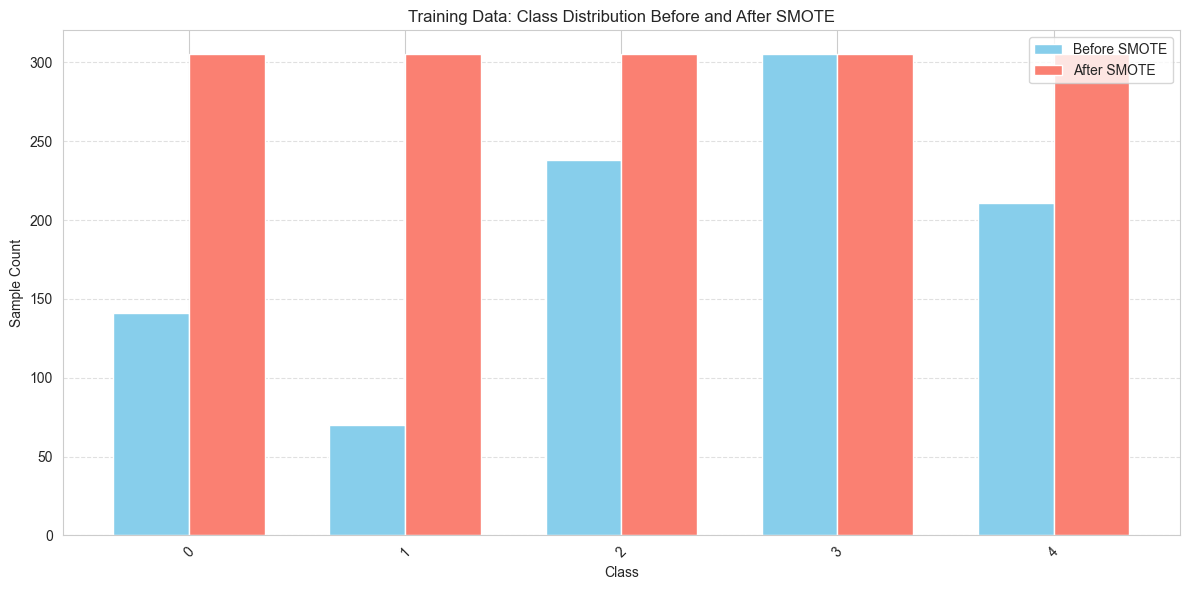

Accuracy: 0.9876, F1 Score: 0.9876, Recall: 0.9876, Runtime: 1.03 sec


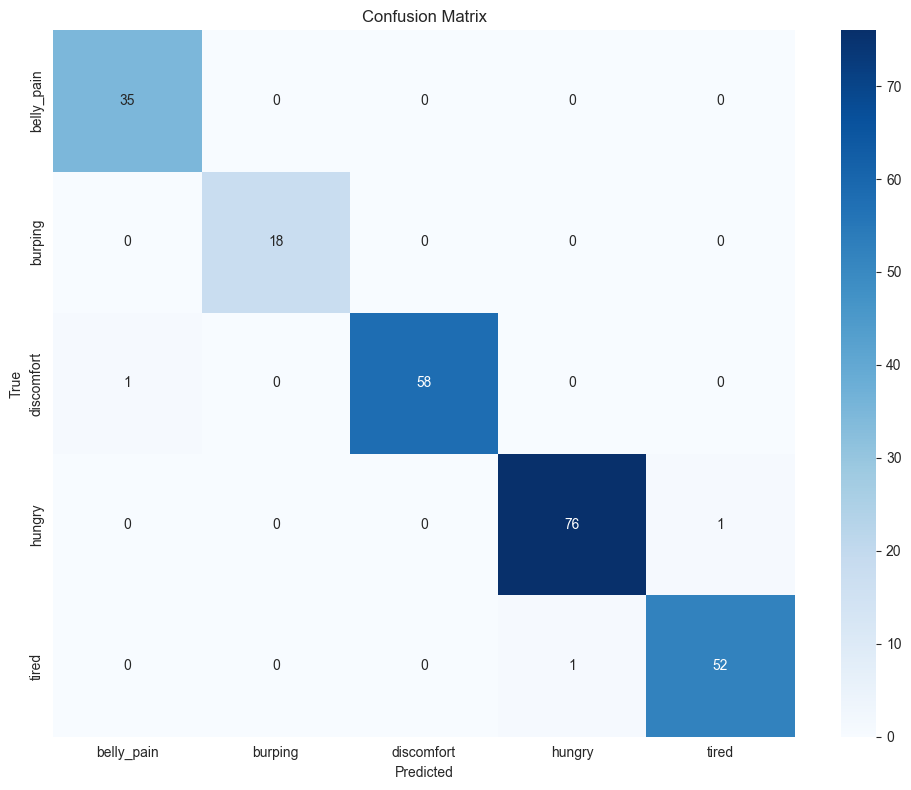

C:\Users\visha\AppData\Local\Temp\ipykernel_28736\3231290717.py:345: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(top_importance), y=list(top_features), palette="viridis")


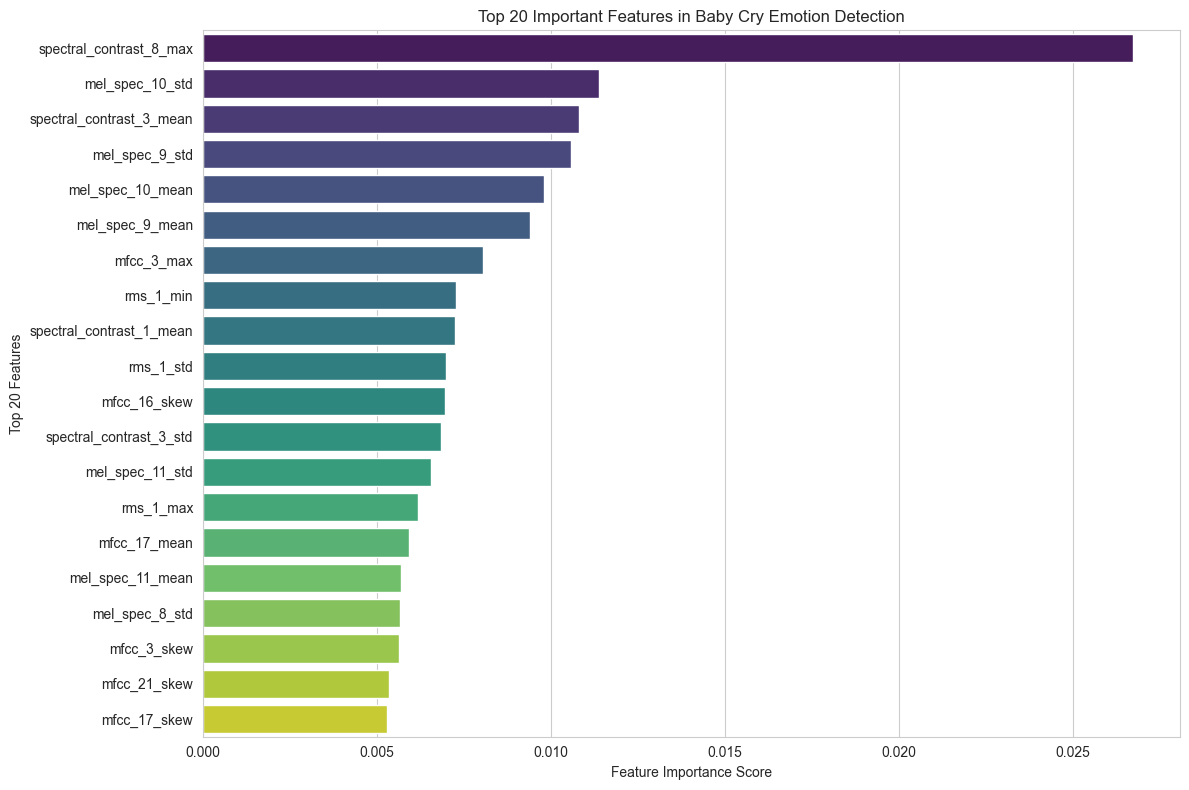


Top 20 Important Features:
spectral_contrast_8_max: 0.0267
mel_spec_10_std: 0.0114
spectral_contrast_3_mean: 0.0108
mel_spec_9_std: 0.0106
mel_spec_10_mean: 0.0098
mel_spec_9_mean: 0.0094
mfcc_3_max: 0.0080
rms_1_min: 0.0073
spectral_contrast_1_mean: 0.0072
rms_1_std: 0.0070
mfcc_16_skew: 0.0070
spectral_contrast_3_std: 0.0068
mel_spec_11_std: 0.0065
rms_1_max: 0.0062
mfcc_17_mean: 0.0059
mel_spec_11_mean: 0.0057
mel_spec_8_std: 0.0056
mfcc_3_skew: 0.0056
mfcc_21_skew: 0.0054
mfcc_17_skew: 0.0053
Model saved as 'baby_cry_model2.pkl


In [12]:
import os
import numpy as np
import librosa
import scipy.signal as signal
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix
import time
import random
from imblearn.over_sampling import SMOTE
from collections import Counter
from scipy.stats import skew, kurtosis
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

SEED = 12345  # You can change this to any integer you want
np.random.seed(SEED)
random.seed(SEED)

# **Pre-emphasis Function**
def pre_emphasis(signal, alpha=0.97):
    return np.append(signal[0], signal[1:] - alpha * signal[:-1])

# **Bandpass Filter Function (142.91 Hz - 6620.12 Hz)**
def bandpass_filter(y, sr=16000, lowcut=142.91, highcut=6620.12, order=5):
    nyquist = 0.5 * sr
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = signal.butter(order, [low, high], btype='band')
    return signal.filtfilt(b, a, y)


def extract_features(audio_data, sr=16000, n_mfcc=40, n_fft=1024, hop_length=160, win_length=400, window='hann',
                     n_chroma=12, n_mels=13, n_bands=7, fmin=100, bins_per_octave=12, tempogram_win=384, spectral_roll_percent=0.95):
    try:
        # Apply Pre-emphasis
        y = pre_emphasis(audio_data, alpha=0.97)

        # Apply Bandpass Filter
        y = bandpass_filter(y, sr=sr)

        # Zero Crossing Rate & RMS
        zcr = librosa.feature.zero_crossing_rate(y, frame_length=win_length, hop_length=hop_length)
        rms = librosa.feature.rms(y=y, frame_length=win_length, hop_length=hop_length)

        # STFT and Spectral Features
        stft = np.abs(librosa.stft(y, n_fft=n_fft, hop_length=hop_length, win_length=win_length))
        S, phase = librosa.magphase(stft)

        # MFCC and Deltas
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc, n_fft=n_fft, hop_length=hop_length,
                                   win_length=win_length, window=window)
        mfcc_delta = librosa.feature.delta(mfcc)
        mfcc_delta2 = librosa.feature.delta(mfcc, order=2)

        # Advanced Spectral Features
        spectral_centroid = librosa.feature.spectral_centroid(S=S, sr=sr)
        spectral_bandwidth = librosa.feature.spectral_bandwidth(S=S, sr=sr)
        spectral_rolloff = librosa.feature.spectral_rolloff(S=S, sr=sr, roll_percent=spectral_roll_percent)
        spectral_contrast = librosa.feature.spectral_contrast(S=S, sr=sr, n_bands=n_bands, fmin=fmin)
        chroma = librosa.feature.chroma_stft(S=S, sr=sr, n_chroma=n_chroma)
        mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length,
                                                 win_length=win_length, n_mels=n_mels)
        tonnetz = librosa.feature.tonnetz(y=y, sr=sr)

        # Temporal Features

        # Feature aggregation with statistics
        feature_functions = [
            (mfcc, 'mfcc', ['mean', 'std', 'skew', 'max', 'min']),
            (mfcc_delta, 'mfcc_delta', ['mean', 'std']),
            (mfcc_delta2, 'mfcc_delta2', ['mean', 'std']),
            (zcr, 'zcr', ['mean', 'std', 'max']),
            (rms, 'rms', ['mean', 'std', 'max', 'min']),
            (spectral_centroid, 'spectral_centroid', ['mean', 'std', 'max']),
            (spectral_bandwidth, 'spectral_bandwidth', ['mean', 'std', 'max']),
            (spectral_rolloff, 'spectral_rolloff', ['mean', 'std']),
            (spectral_contrast, 'spectral_contrast', ['mean', 'std', 'max']),
            (chroma, 'chroma', ['mean', 'std']),
            (mel_spec, 'mel_spec', ['mean', 'std']),
            (tonnetz, 'tonnetz', ['mean', 'std']),
        ]

        features = []
        feature_names = []

        for feat, feat_name, stats in feature_functions:
            for i in range(feat.shape[0]):
                if 'mean' in stats: 
                    features.append(np.mean(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_mean")
                if 'std' in stats: 
                    features.append(np.std(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_std")
                if 'skew' in stats: 
                    features.append(skew(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_skew")
                if 'kurt' in stats: 
                    features.append(kurtosis(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_kurt")
                if 'max' in stats: 
                    features.append(np.max(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_max")
                if 'min' in stats: 
                    features.append(np.min(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_min")

        # Return both features and their names
        return np.array(features), feature_names
    except Exception as e:
        print(f"Error processing audio data: {e}")
        return None, None


# **Data Augmentation Functions**
def time_stretching(y, rate):
    """Time stretching without changing pitch"""
    return librosa.effects.time_stretch(y, rate=rate)

def pitch_shifting(y, sr, n_steps):
    """Pitch shifting without changing tempo"""
    return librosa.effects.pitch_shift(y, sr=sr, n_steps=n_steps)

def add_noise(y, noise_factor=0.005):
    """Add random noise to the audio"""
    noise = np.random.randn(len(y))
    return y + noise_factor * noise

def random_gain(y, min_factor=0.7, max_factor=1.3):
    """Apply random gain to the audio"""
    gain_factor = np.random.uniform(min_factor, max_factor)
    return y * gain_factor

def time_shifting(y, shift_factor=0.2):
    """Shift audio in time (circular shift)"""
    shift_amount = int(len(y) * shift_factor)
    return np.roll(y, shift_amount)

def augment_audio(y, sr):
    """Apply random augmentation technique to audio"""
    augmentation_techniques = [
        lambda: time_stretching(y, rate=np.random.uniform(0.85, 1.15)),
        lambda: pitch_shifting(y, sr, n_steps=np.random.uniform(-2, 2)),
        lambda: add_noise(y, noise_factor=np.random.uniform(0.001, 0.01)),
        lambda: random_gain(y),
        lambda: time_shifting(y, shift_factor=np.random.uniform(0.1, 0.3))
    ]
    
    # Randomly select two augmentation techniques
    chosen_techniques = np.random.choice(len(augmentation_techniques), size=2, replace=False)
    
    augmented_y = y.copy()
    for idx in chosen_techniques:
        augmented_y = augmentation_techniques[idx]()
    
    return augmented_y

# Global variable to store feature names
all_feature_names = []

# **Load Dataset with Augmentation**
path = r"C:\Users\visha\OneDrive\Desktop\SEM6\Speech Processing\datasets\donateacry_corpus"
features = []
labels = []

# Get initial class counts to determine augmentation needed
initial_counts = {}
for label in os.listdir(path):
    file_count = len(os.listdir(os.path.join(path, label)))
    initial_counts[label] = file_count
    
print("Initial class distribution:")
for label, count in initial_counts.items():
    print(f"{label}: {count} samples")

# Find majority class
majority_class_count = max(initial_counts.values())

# **Extract Features with Augmentation**
for label in os.listdir(path):
    print(f"{label} data is loading...")
    label_files = os.listdir(os.path.join(path, label))
    augmentation_factor = int(np.ceil(majority_class_count / len(label_files))) - 1
    
    # Process original files
    for file_name in label_files:
        file_path = os.path.join(path, label, file_name)
        
        # Load audio file
        y, sr = librosa.load(file_path, sr=16000)
        
        # Extract features from original audio
        feature, feature_names = extract_features(y, sr=sr)
        if feature is not None:
            features.append(feature)
            labels.append(label)
            
            # Store feature names only once
            if not all_feature_names and feature_names is not None:
                all_feature_names = feature_names
        
        # Apply augmentation if needed (for minority classes)
        if augmentation_factor > 0:
            for _ in range(min(augmentation_factor, 10)):  # Cap at 10 augmentations per file
                augmented_y = augment_audio(y, sr)
                augmented_feature, _ = extract_features(augmented_y, sr=sr)
                if augmented_feature is not None:
                    features.append(augmented_feature)
                    labels.append(label)
    
    print(f"{label} data loaded with augmentation...")

# Check if feature dimensions are consistent
feature_lengths = [len(f) for f in features]
if len(set(feature_lengths)) > 1:
    print(f"Warning: Inconsistent feature lengths detected: {set(feature_lengths)}")
    # Find the most common length
    from collections import Counter
    most_common_length = Counter(feature_lengths).most_common(1)[0][0]
    
    # Filter to keep only features with the most common length
    valid_indices = [i for i, length in enumerate(feature_lengths) if length == most_common_length]
    features = [features[i] for i in valid_indices]
    labels = [labels[i] for i in valid_indices]
    print(f"Filtered to {len(features)} samples with consistent feature length of {most_common_length}")

# **Convert to NumPy Arrays**
features = np.array(features)
labels = np.array(labels)

# Show class distribution after augmentation
print("\nClass distribution after augmentation:")
for label, count in Counter(labels).items():
    print(f"{label}: {count} samples")

# **Encode Labels**
le = LabelEncoder()
labels = le.fit_transform(labels)

# **Generate Random Seeds**
split_seed = 3225806193
model_seed = 3613533475

# **Print the Seeds Used**
print(f"Train-Test Split Seed: {split_seed}")
print(f"Random Forest Seed: {model_seed}")

# **Split Data**
X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.20, random_state=split_seed, stratify=labels)

# Apply SMOTE for balancing the training data
y_train_before_smote = y_train.copy()
smote = SMOTE(random_state=model_seed)
X_train, y_train = smote.fit_resample(X_train, y_train)


print(f"Training data shape after SMOTE: {X_train.shape}")
print(f"Number of features: {X_train.shape[1]}")

# Step 4: Plot distributions
def plot_class_distribution(y_before, y_after, title_prefix=""):
    before_counts = Counter(y_before)
    after_counts = Counter(y_after)

    classes = sorted(before_counts.keys())
    
    plt.figure(figsize=(12, 6))
    bar_width = 0.35
    x = range(len(classes))
    
    plt.bar(x, [before_counts[cls] for cls in classes], 
            width=bar_width, label='Before SMOTE', color='skyblue')
    
    plt.bar([i + bar_width for i in x], [after_counts[cls] for cls in classes], 
            width=bar_width, label='After SMOTE', color='salmon')
    
    plt.xlabel('Class')
    plt.ylabel('Sample Count')
    plt.title(f'{title_prefix}Class Distribution Before and After SMOTE')
    plt.xticks([i + bar_width / 2 for i in x], classes, rotation=45)
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

# Call the plot function
plot_class_distribution(y_train_before_smote, y_train, title_prefix="Training Data: ")

# **Train Weighted Random Forest Classifier**
start_time = time.time()
rf = RandomForestClassifier(
    n_estimators=500, 
    max_depth=20, 
    class_weight="balanced", 
    random_state=model_seed,
    n_jobs=-1  # Use all available cores
)
rf.fit(X_train, y_train)
runtime = time.time() - start_time

# **Predict**
y_pred = rf.predict(X_test)

# **Evaluate Performance**
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")

# **Print Results**
print(f"Accuracy: {accuracy:.4f}, F1 Score: {f1:.4f}, Recall: {recall:.4f}, Runtime: {runtime:.2f} sec")

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)
class_names = le.classes_

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.savefig('confusion_matrix.png')
plt.show()

# Get feature importances
if len(all_feature_names) == X_train.shape[1]:
    feature_importances = rf.feature_importances_
    feature_importance_dict = dict(zip(all_feature_names, feature_importances))
    
    # **Sort and Get Top 20 Features**
    sorted_features = sorted(feature_importance_dict.items(), key=lambda x: x[1], reverse=True)[:20]
    top_features, top_importance = zip(*sorted_features)
    
    # Print top 20 features with importance sco
    
    # **Plot Feature Importance**
    plt.figure(figsize=(12, 8))
    sns.barplot(x=list(top_importance), y=list(top_features), palette="viridis")
    plt.xlabel("Feature Importance Score")
    plt.ylabel("Top 20 Features")
    plt.title("Top 20 Important Features in Baby Cry Emotion Detection")
    plt.tight_layout()
    plt.savefig('feature_importance.png')
    plt.show()
    
    # Print top 20 features with importance scores
    print("\nTop 20 Important Features:")
    for feature, importance in sorted_features:
        print(f"{feature}: {importance:.4f}")
else:
    print(f"Error: Feature names count ({len(all_feature_names)}) doesn't match feature count ({X_train.shape[1]})")
    # Use generic feature names as fallback
    generic_feature_names = [f"feature_{i}" for i in range(X_train.shape[1])]
    feature_importances = rf.feature_importances_
    feature_importance_dict = dict(zip(generic_feature_names, feature_importances))
    
    # Sort and get top 20
    sorted_features = sorted(feature_importance_dict.items(), key=lambda x: x[1], reverse=True)[:20]
    top_features, top_importance = zip(*sorted_features)
    
    plt.figure(figsize=(12, 8))
    sns.barplot(x=list(top_importance), y=list(top_features), palette="viridis")
    plt.xlabel("Feature Importance Score")
    plt.ylabel("Top 20 Features")
    plt.title("Top 20 Important Features in Baby Cry Emotion Detection")
    plt.tight_layout()
    plt.savefig('feature_importance.png')
    plt.show()

# Save the model and feature names for future use
import pickle
model_info = {
    'model': rf,
    'feature_names': all_feature_names,
    'class_names': class_names,
    'performance': {
        'accuracy': accuracy,
        'f1': f1,
        'recall': recall
    }
}

with open('baby_cry_model2.pkl', 'wb') as f:
    pickle.dump(model_info, f)

print("Model saved as 'baby_cry_model2.pkl")